In [396]:
# library

pd.set_option("display.float_format", "{:,.2f}".format)

import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, StratifiedShuffleSplit
from sklearn.feature_selection import SelectKBest, f_regression, VarianceThreshold
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics.pairwise import haversine_distances
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# Get the Data

In [326]:
california_data = fetch_california_housing()
data = pd.DataFrame(california_data.data, columns=california_data.feature_names)
data['target'] = california_data.target

data.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,target
0,8.33,41.00,6.98,1.02,322.00,2.56,37.88,-122.23,4.53
1,8.30,21.00,6.24,0.97,"2,401.00",2.11,37.86,-122.22,3.58
2,7.26,52.00,8.29,1.07,496.00,2.80,37.85,-122.24,3.52
3,5.64,52.00,5.82,1.07,558.00,2.55,37.85,-122.25,3.41
4,3.85,52.00,6.28,1.08,565.00,2.18,37.85,-122.25,3.42


In [327]:
print(california_data.DESCR)

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib repository.
https://www.dcc.fc.up.pt/~ltorgo/Regression/cal_housing.html

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per ce

In [328]:
""" 
1. MedInc - Median Income
- Menjelaskan median pendapatan rumah tangga (household) dalam suatu census block group / wilayah.

2. AveRooms - Average Rooms
- Menjelaskan rata-rata jumlah ruangan per rumah tangga (household) dalam satu census block group / wilayah.

3. AveBedrms = Average Bedrooms
- Menjelaskan rata-rata jumlah kamar tidur per rumah tangga dalam satu census block group / wilayah.

4. Population
- Menjelaskan total jumlah penduduk yang tinggal dalam satu census block group / wilayah.

5. AveOccup - Average Occupancy
- AveOccup menjelaskan rata-rata jumlah orang yang tinggal dalam satu rumah tangga (household) di suatu census block group / wilayah.

6. Median House Value (Target)
- Menjelaskan median nilai/harga rumah dalam satu census block group / wilayah, bukan harga satu rumah tertentu.

7. Latitude dan Longitude
Bayangkan California dibagi menjadi banyak wilayah kecil (census block groups). Setiap wilayah memiliki:
- Latitude dan Longitude sebagai informasi lokasi.
- Median income penduduk.
- Rata-rata jumlah ruangan rumah.
- Rata-rata jumlah kamar tidur.
- Jumlah penduduk.
- Rata-rata jumlah penghuni rumah.
- Median nilai rumah.

Ilustrasi datanya ada di dalam dataset. Angka yang ada di dataset dalam satu baris merupakan satu wilayah, bukan satu rumah

"""

' \n1. MedInc - Median Income\n- Menjelaskan median pendapatan rumah tangga (household) dalam suatu census block group / wilayah.\n\n2. AveRooms - Average Rooms\n- Menjelaskan rata-rata jumlah ruangan per rumah tangga (household) dalam satu census block group / wilayah.\n\n3. AveBedrms = Average Bedrooms\n- Menjelaskan rata-rata jumlah kamar tidur per rumah tangga dalam satu census block group / wilayah.\n\n4. Population\n- Menjelaskan total jumlah penduduk yang tinggal dalam satu census block group / wilayah.\n\n5. AveOccup - Average Occupancy\n- AveOccup menjelaskan rata-rata jumlah orang yang tinggal dalam satu rumah tangga (household) di suatu census block group / wilayah.\n\n6. Median House Value (Target)\n- Menjelaskan median nilai/harga rumah dalam satu census block group / wilayah, bukan harga satu rumah tertentu.\n\n7. Latitude dan Longitude\nBayangkan California dibagi menjadi banyak wilayah kecil (census block groups). Setiap wilayah memiliki:\n- Latitude dan Longitude sebag

In [329]:
count_latlon = data.groupby(['Latitude', 'Longitude'])['Population'].sum().reset_index()
count_latlon[['Latitude', 'Longitude']].value_counts().reset_index()

,Latitude,Longitude,count
0,32.54,-117.04,1
1,37.45,-121.90,1
2,37.45,-121.06,1
3,37.45,-120.89,1
4,37.46,-122.34,1
...,...,...,...
12585,34.09,-117.33,1
12586,34.09,-117.32,1
12587,34.09,-117.31,1
12588,34.09,-117.30,1


In [330]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      20640 non-null  float64
 1   HouseAge    20640 non-null  float64
 2   AveRooms    20640 non-null  float64
 3   AveBedrms   20640 non-null  float64
 4   Population  20640 non-null  float64
 5   AveOccup    20640 non-null  float64
 6   Latitude    20640 non-null  float64
 7   Longitude   20640 non-null  float64
 8   target      20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


## Overview the Data

In [331]:
data[["MedInc", "HouseAge", "AveRooms", "AveBedrms", "Population", "AveOccup", "target"]].describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,target
count,"20,640.00","20,640.00","20,640.00","20,640.00","20,640.00","20,640.00","20,640.00"
mean,3.87,28.64,5.43,1.10,"1,425.48",3.07,2.07
std,1.90,12.59,2.47,0.47,"1,132.46",10.39,1.15
min,0.50,1.00,0.85,0.33,3.00,0.69,0.15
25%,2.56,18.00,4.44,1.01,787.00,2.43,1.20
50%,3.53,29.00,5.23,1.05,"1,166.00",2.82,1.80
75%,4.74,37.00,6.05,1.10,"1,725.00",3.28,2.65
max,15.00,52.00,141.91,34.07,"35,682.00","1,243.33",5.00


In [332]:
def overview_data(data):
    missing_values = data.isna().sum()
    pct_missing_values = round((data.isna().sum() / len(data)) * 100, 2)
    duplicated_data = data.duplicated().sum()
    coeff_of_var = (data.std() / data.mean()) * 100

    return pd.DataFrame({
        "missing_data": missing_values,
        "pct_missing_values": pct_missing_values,
        "duplicated_data": duplicated_data,
        "coeff_of_var": coeff_of_var
    })

overview_data(data[["MedInc", "HouseAge", "AveRooms", "AveBedrms", "Population", "AveOccup", "target"]])


,missing_data,pct_missing_values,duplicated_data,coeff_of_var
MedInc,0,0.00,0,49.08
HouseAge,0,0.00,0,43.94
AveRooms,0,0.00,0,45.57
AveBedrms,0,0.00,0,43.21
Population,0,0.00,0,79.44
AveOccup,0,0.00,0,338.24
target,0,0.00,0,55.79


In [333]:
""" 
Kolom MedInc:
- mean > median maka distribusi data mungking menceng ke kanan
- std < mean maka variasi datanya kecil, tetapi belum cukup menyimpulkan variasinya kecil karena nilai CV 49.80% menunjukkan variasi relatif cukup besar
- rentang min dan max yang jauh adanya kemungkinan nilai ekstrem/outlier
- rentang quartile 25% / Q1 dengan nilai min itu relatif pendek
- rentang quartile 75% / Q3  dengan nilai max itu lebar, adanya kemungkinan nilai ekstrem/outlier
- jarak Q1 ke min lebih pendek dibandigkan dengan jarak Q3 ke max, artinya ada kemungkinan ekor distribusi lebih panjang ke kanan 

Kolom HouseAge:
- mean < median maka distribusi data mungkin menceng ke kiri
- std < mean maka variasi datanya kecil, tetapi belum cukup menyimpulkan variasinya kecil karena nilai CV 43.94% menunjukkan variasi relatif cukup besar
- rentang min dan max yang jauh adanya kemungkinan nilai ekstrem/outlier
- rentang quartile 25% / Q1 dengan nilai min itu lebar, adanya kemungkinan nilai ekstrem/outlier
- rentang quartile 75% / Q3  dengan nilai max itu relatif lebar, adanya kemungkinan nilai ekstrem/outlier
- jarak Q1 ke min itu sama lebarnya dibandigkan dengan jarak Q3 ke max, artinya ada kemungkinan penyebarannya relatif seimbang

Kolom AveRooms:
- mean > median maka distribusi data mungking menceng ke kanan
- std < mean maka variasi datanya kecil, tetapi belum cukup menyimpulkan variasinya kecil karena nilai CV 45.57% menunjukkan variasi relatif cukup besar
- rentang min dan max yang jauh adanya kemungkinan nilai ekstrem/outlier
- rentang quartile 25% / Q1 dengan nilai min itu relatif pendek
- rentang quartile 75% / Q3  dengan nilai max itu lebar, adanya kemungkinan nilai ekstrem/outlier
- jarak Q1 ke min lebih pendek dibandigkan dengan jarak Q3 ke max, artinya ada kemungkinan ekor distribusi lebih panjang ke kanan 

Kolom AveBedrms:
- mean > median maka distribusi data mungking menceng ke kanan
- std < mean maka variasi datanya kecil, tetapi belum cukup menyimpulkan variasinya kecil karena nilai CV 43.21% menunjukkan variasi relatif cukup besar
- rentang min dan max yang jauh adanya kemungkinan nilai ekstrem/outlier
- rentang quartile 25% / Q1 dengan nilai min itu relatif pendek
- rentang quartile 75% / Q3  dengan nilai max itu lebar, adanya kemungkinan nilai ekstrem/outlier
- jarak Q1 ke min lebih pendek dibandigkan dengan jarak Q3 ke max, artinya ada kemungkinan ekor distribusi lebih panjang ke kanan 

Kolom Population:
- mean > median maka distribusi data mungking menceng ke kanan
- std < mean maka variasi datanya kecil, tetapi belum cukup menyimpulkan variasinya kecil karena nilai CV 79.44% menunjukkan variasi yang besar
- rentang min dan max yang jauh adanya kemungkinan nilai ekstrem/outlier
- rentang quartile 25% / Q1 dengan nilai min itu lebar, adanya kemungkinan nilai ekstrem/outlier
- rentang quartile 75% / Q3  dengan nilai max itu lebar, adanya kemungkinan nilai ekstrem/outlier
- jarak Q1 ke min itu sama lebarnya dibandigkan dengan jarak Q3 ke max, artinya ada kemungkinan penyebarannya relatif seimbang

Kolom AveOccup:
- mean > median maka distribusi data mungking menceng ke kanan
- std > mean maka variasi datanya besar
- rentang min dan max yang jauh adanya kemungkinan nilai ekstrem/outlier
- rentang quartile 25% / Q1 dengan nilai min itu relatif pendek
- rentang quartile 75% / Q3  dengan nilai max itu lebar, adanya kemungkinan nilai ekstrem/outlier
- jarak Q1 ke min lebih pendek dibandigkan dengan jarak Q3 ke max, artinya ada kemungkinan ekor distribusi lebih panjang ke kanan

Kolom Target:
- mean > median maka distribusi data mungking menceng ke kanan
- std < mean maka variasi datanya kecil, tetapi belum cukup menyimpulkan variasinya kecil karena nilai CV 55.78% menunjukkan variasi relatif cukup besar
- rentang min dan max yang cukup lebar
- rentang quartile 25% / Q1 dengan nilai min itu relatif pendek
- rentang quartile 75% / Q3  dengan nilai max itu lebar, adanya kemungkinan nilai ekstrem/outlier
- jarak Q1 ke min lebih pendek dibandigkan dengan jarak Q3 ke max, artinya ada kemungkinan ekor distribusi lebih panjang ke kanan
"""

' \nKolom MedInc:\n- mean > median maka distribusi data mungking menceng ke kanan\n- std < mean maka variasi datanya kecil, tetapi belum cukup menyimpulkan variasinya kecil karena nilai CV 49.80% menunjukkan variasi relatif cukup besar\n- rentang min dan max yang jauh adanya kemungkinan nilai ekstrem/outlier\n- rentang quartile 25% / Q1 dengan nilai min itu relatif pendek\n- rentang quartile 75% / Q3  dengan nilai max itu lebar, adanya kemungkinan nilai ekstrem/outlier\n- jarak Q1 ke min lebih pendek dibandigkan dengan jarak Q3 ke max, artinya ada kemungkinan ekor distribusi lebih panjang ke kanan \n\nKolom HouseAge:\n- mean < median maka distribusi data mungkin menceng ke kiri\n- std < mean maka variasi datanya kecil, tetapi belum cukup menyimpulkan variasinya kecil karena nilai CV 43.94% menunjukkan variasi relatif cukup besar\n- rentang min dan max yang jauh adanya kemungkinan nilai ekstrem/outlier\n- rentang quartile 25% / Q1 dengan nilai min itu lebar, adanya kemungkinan nilai eks

array([[<Axes: title={'center': 'MedInc'}>,
        <Axes: title={'center': 'HouseAge'}>,
        <Axes: title={'center': 'AveRooms'}>],
       [<Axes: title={'center': 'AveBedrms'}>,
        <Axes: title={'center': 'Population'}>,
        <Axes: title={'center': 'AveOccup'}>],
       [<Axes: title={'center': 'target'}>, <Axes: >, <Axes: >]],
      dtype=object)

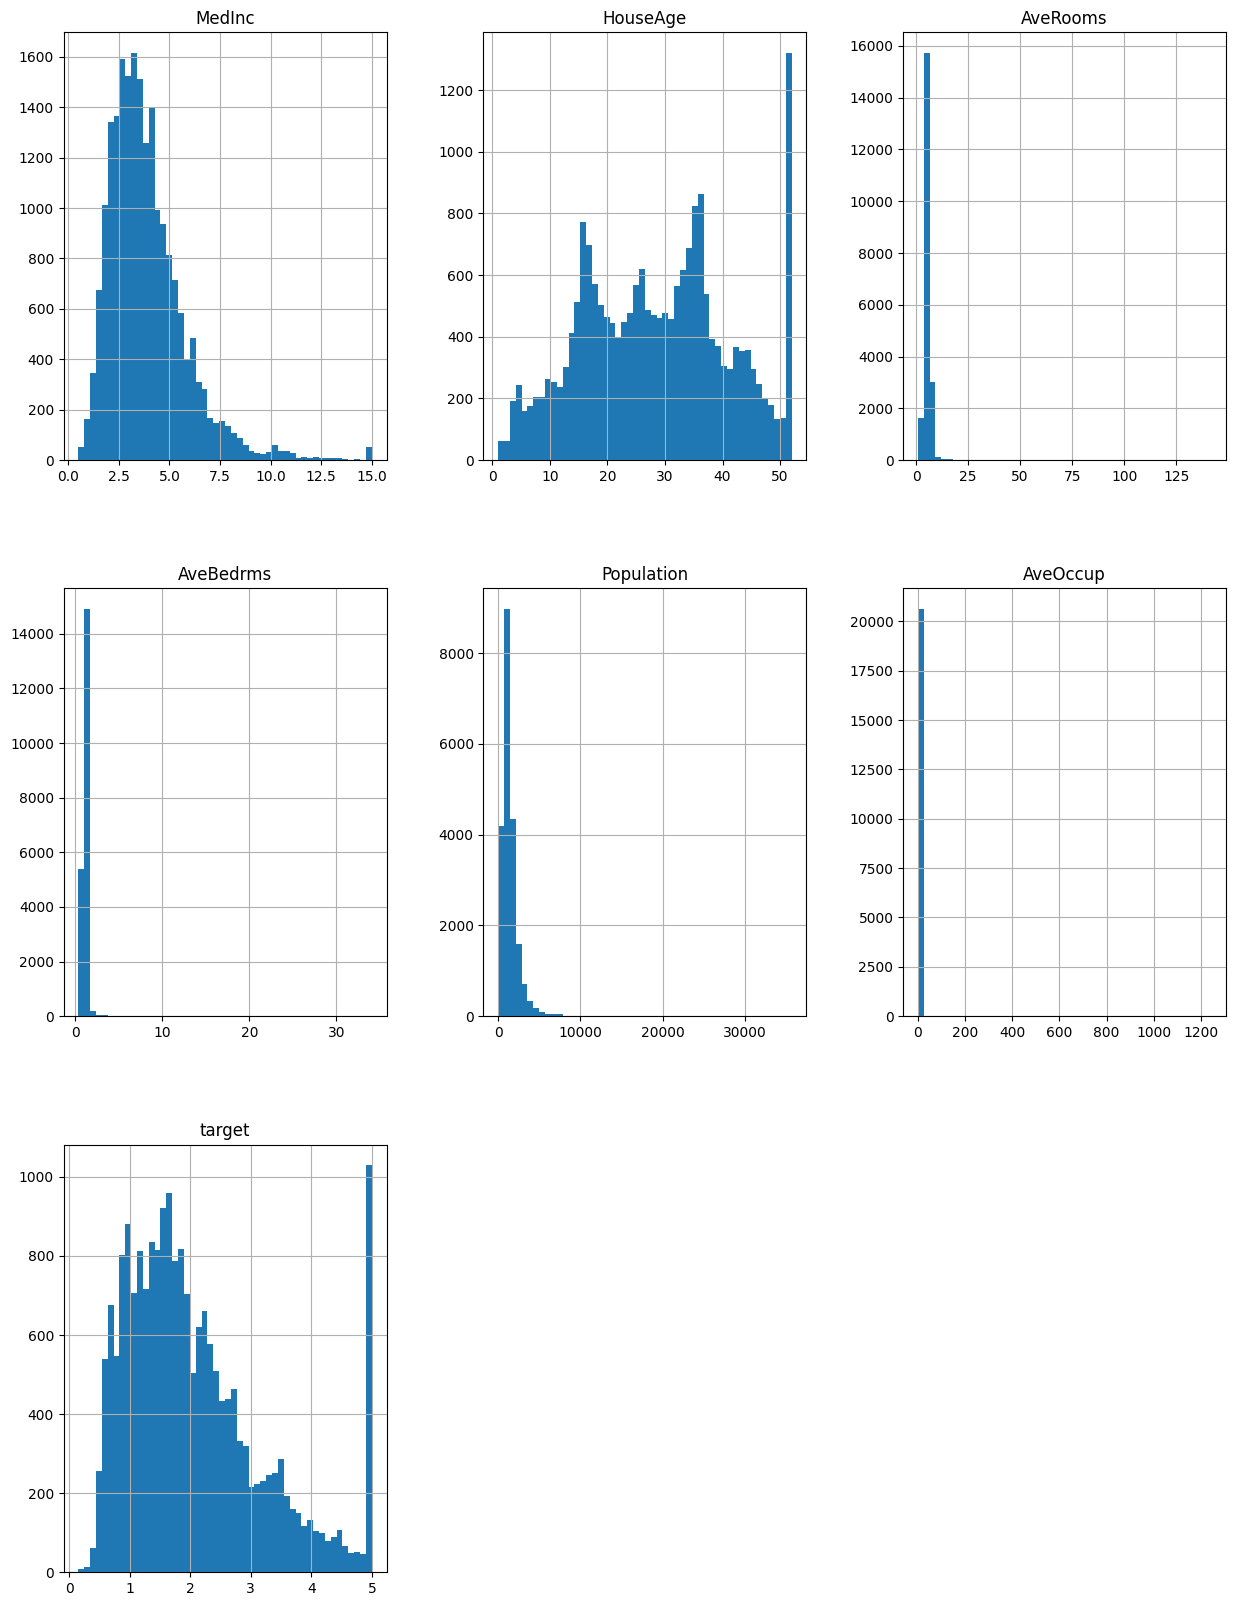

In [334]:
data[["MedInc", "HouseAge", "AveRooms", "AveBedrms", "Population", "AveOccup", "target"]].hist(bins=50, figsize=(15, 20))

In [335]:
""" 
1. Kolom MedInc
- Mean > median maka distribusi data mungking menceng ke kanan.
- Std < mean maka variasi datanya kecil, tetapi belum cukup menyimpulkan variasinya kecil karena nilai CV 49.80% menunjukkan variasi relatif cukup besar.
- Rentang min dan max yang jauh adanya kemungkinan nilai ekstrem/outlier.
- Rentang quartile 25% / Q1 dengan nilai min itu relatif pendek.
- Rentang quartile 75% / Q3 dengan nilai max itu lebar, adanya kemungkinan nilai ekstrem/outlier.
- Jarak Q1 ke min lebih pendek dibandigkan dengan jarak Q3 ke max, artinya ada kemungkinan ekor distribusi lebih panjang ke kanan.
- Berdasarkan histogram: distribusi terlihat right-skewed. Sebagian besar data terkonsentrasi di sekitar nilai 2-5, kemudian frekuensinya semakin menurun ke arah kanan.
- Tambahan: terlihat lonjakan pada nilai sekitar 15. Hal ini kemungkinan berkaitan dengan adanya batas maksimum nilai MedInc pada dataset.

2. Kolom HouseAge
- Mean < median maka distribusi data mungkin menceng ke kiri.
- Std < mean maka variasi datanya kecil, tetapi belum cukup menyimpulkan variasinya kecil karena nilai CV 43.94% menunjukkan variasi relatif cukup besar.
- Rentang min dan max yang jauh adanya kemungkinan nilai ekstrem/outlier.
- Rentang quartile 25% / Q1 dengan nilai min itu lebar, adanya kemungkinan nilai ekstrem/outlier.
- Rentang quartile 75% / Q3 dengan nilai max itu relatif lebar, adanya kemungkinan nilai ekstrem/outlier.
- Jarak Q1 ke min itu sama lebarnya dibandigkan dengan jarak Q3 ke max, artinya ada kemungkinan penyebarannya relatif seimbang.
- Berdasarkan histogram: distribusi tidak terlihat membentuk pola normal atau satu puncak yang simetris. Terlihat beberapa puncak (multiple peaks atau multimodal), yang menunjukkan adanya beberapa kelompok nilai HouseAge dengan frekuensi cukup tinggi.
- Tambahan: terdapat lonjakan yang sangat tinggi pada nilai sekitar 52. Kemungkinan ini disebabkan oleh batas maksimum nilai HouseAge pada dataset (capped values).

3. Kolom AveRooms
- Mean > median maka distribusi data mungking menceng ke kanan.
- Std < mean maka variasi datanya kecil, tetapi belum cukup menyimpulkan variasinya kecil karena nilai CV 45.57% menunjukkan variasi relatif cukup besar.
- Rentang min dan max yang jauh adanya kemungkinan nilai ekstrem/outlier.
- Rentang quartile 25% / Q1 dengan nilai min itu relatif pendek.
- Rentang quartile 75% / Q3 dengan nilai max itu lebar, adanya kemungkinan nilai ekstrem/outlier.
- Jarak Q1 ke min lebih pendek dibandigkan dengan jarak Q3 ke max, artinya ada kemungkinan ekor distribusi lebih panjang ke kanan.
- Berdasarkan histogram: distribusi terlihat sangat menceng ke kanan (highly right-skewed). Sebagian besar data terkonsentrasi pada nilai yang rendah, sementara terdapat sedikit data dengan nilai yang sangat tinggi.
- Tambahan: terlihat beberapa nilai yang jauh dari konsentrasi utama data. Hal ini mengindikasikan adanya kemungkinan outlier yang cukup ekstrem.

4. Kolom AveBedrms
- Mean > median maka distribusi data mungking menceng ke kanan.
- Std < mean maka variasi datanya kecil, tetapi belum cukup menyimpulkan variasinya kecil karena nilai CV 43.21% menunjukkan variasi relatif cukup besar.
- Rentang min dan max yang jauh adanya kemungkinan nilai ekstrem/outlier.
- Rentang quartile 25% / Q1 dengan nilai min itu relatif pendek.
- Rentang quartile 75% / Q3 dengan nilai max itu lebar, adanya kemungkinan nilai ekstrem/outlier.
- Jarak Q1 ke min lebih pendek dibandigkan dengan jarak Q3 ke max, artinya ada kemungkinan ekor distribusi lebih panjang ke kanan.
- Berdasarkan histogram: distribusi terlihat menceng ke kanan (right-skewed). Sebagian besar data terkonsentrasi pada nilai yang rendah, sedangkan frekuensi semakin menurun pada nilai yang lebih tinggi.
- Tambahan: terlihat adanya sejumlah kecil nilai yang jauh dari konsentrasi utama data, sehingga perlu diperiksa lebih lanjut sebagai kemungkinan outlier.

5. Kolom Population
- Mean > median maka distribusi data mungking menceng ke kanan.
- Std < mean maka variasi datanya kecil, tetapi belum cukup menyimpulkan variasinya kecil karena nilai CV 79.44% menunjukkan variasi yang besar.
- Rentang min dan max yang jauh adanya kemungkinan nilai ekstrem/outlier.
- Rentang quartile 25% / Q1 dengan nilai min itu lebar, adanya kemungkinan nilai ekstrem/outlier.
- Rentang quartile 75% / Q3 dengan nilai max itu lebar, adanya kemungkinan nilai ekstrem/outlier.
- Jarak Q1 ke min itu sama lebarnya dibandigkan dengan jarak Q3 ke max, artinya ada kemungkinan penyebarannya relatif seimbang.
- Berdasarkan histogram: distribusi terlihat sangat menceng ke kanan (right-skewed). Sebagian besar block group memiliki populasi relatif rendah, sedangkan hanya sedikit block group yang memiliki populasi sangat tinggi.
- Tambahan: terlihat ekor distribusi yang panjang ke kanan. Beberapa nilai populasi berada jauh dari konsentrasi utama data dan berpotensi menjadi outlier.

6. Kolom AveOccup
- Mean > median maka distribusi data mungking menceng ke kanan.
- Std > mean maka variasi datanya besar.
- Rentang min dan max yang jauh adanya kemungkinan nilai ekstrem/outlier.
- Rentang quartile 25% / Q1 dengan nilai min itu relatif pendek.
- Rentang quartile 75% / Q3 dengan nilai max itu lebar, adanya kemungkinan nilai ekstrem/outlier.
- Jarak Q1 ke min lebih pendek dibandigkan dengan jarak Q3 ke max, artinya ada kemungkinan ekor distribusi lebih panjang ke kanan.
- Berdasarkan histogram: distribusi terlihat sangat menceng ke kanan (extremely right-skewed). Hampir seluruh data terkonsentrasi pada nilai yang sangat rendah, sementara terdapat sedikit data dengan nilai yang sangat tinggi.
- Tambahan: terlihat beberapa nilai yang sangat jauh dari mayoritas data. Hal ini mengindikasikan kemungkinan adanya outlier ekstrem yang perlu diperiksa lebih lanjut.

7. Kolom Target
- Mean > median maka distribusi data mungking menceng ke kanan.
- Std < mean maka variasi datanya kecil, tetapi belum cukup menyimpulkan variasinya kecil karena nilai CV 55.78% menunjukkan variasi relatif cukup besar.
- Rentang min dan max yang cukup lebar.
- Rentang quartile 25% / Q1 dengan nilai min itu relatif pendek.
- Rentang quartile 75% / Q3 dengan nilai max itu lebar, adanya kemungkinan nilai ekstrem/outlier.
- Jarak Q1 ke min lebih pendek dibandigkan dengan jarak Q3 ke max, artinya ada kemungkinan ekor distribusi lebih panjang ke kanan.
- Berdasarkan histogram: distribusi terlihat menceng ke kanan (right-skewed). Sebagian besar nilai target terkonsentrasi pada rentang sekitar 1-2, kemudian frekuensinya semakin menurun ke arah kanan.
- Tambahan: terdapat lonjakan yang cukup tinggi pada nilai 5. Kemungkinan hal ini disebabkan oleh batas maksimum nilai target pada dataset (capped values), sehingga beberapa nilai yang sebenarnya lebih tinggi tercatat sebagai 5.
"""

' \n1. Kolom MedInc\n- Mean > median maka distribusi data mungking menceng ke kanan.\n- Std < mean maka variasi datanya kecil, tetapi belum cukup menyimpulkan variasinya kecil karena nilai CV 49.80% menunjukkan variasi relatif cukup besar.\n- Rentang min dan max yang jauh adanya kemungkinan nilai ekstrem/outlier.\n- Rentang quartile 25% / Q1 dengan nilai min itu relatif pendek.\n- Rentang quartile 75% / Q3 dengan nilai max itu lebar, adanya kemungkinan nilai ekstrem/outlier.\n- Jarak Q1 ke min lebih pendek dibandigkan dengan jarak Q3 ke max, artinya ada kemungkinan ekor distribusi lebih panjang ke kanan.\n- Berdasarkan histogram: distribusi terlihat right-skewed. Sebagian besar data terkonsentrasi di sekitar nilai 2-5, kemudian frekuensinya semakin menurun ke arah kanan.\n- Tambahan: terlihat lonjakan pada nilai sekitar 15. Hal ini kemungkinan berkaitan dengan adanya batas maksimum nilai MedInc pada dataset.\n\n2. Kolom HouseAge\n- Mean < median maka distribusi data mungkin menceng ke 

# Data Wrangling

In [336]:
# Standarisasi nama kolom

data.columns = data.columns.str.lower()
data.head()

,medinc,houseage,averooms,avebedrms,population,aveoccup,latitude,longitude,target
0,8.33,41.00,6.98,1.02,322.00,2.56,37.88,-122.23,4.53
1,8.30,21.00,6.24,0.97,"2,401.00",2.11,37.86,-122.22,3.58
2,7.26,52.00,8.29,1.07,496.00,2.80,37.85,-122.24,3.52
3,5.64,52.00,5.82,1.07,558.00,2.55,37.85,-122.25,3.41
4,3.85,52.00,6.28,1.08,565.00,2.18,37.85,-122.25,3.42


In [337]:
# Memperbaiki nilai pada kolom tertentu sesuai dokumentasi yang aada
data['medinc'] = data['medinc'] * 10000
data['target'] = data['target'] * 100000

data.head()

,medinc,houseage,averooms,avebedrms,population,aveoccup,latitude,longitude,target
0,"83,252.00",41.00,6.98,1.02,322.00,2.56,37.88,-122.23,"452,600.00"
1,"83,014.00",21.00,6.24,0.97,"2,401.00",2.11,37.86,-122.22,"358,500.00"
2,"72,574.00",52.00,8.29,1.07,496.00,2.80,37.85,-122.24,"352,100.00"
3,"56,431.00",52.00,5.82,1.07,558.00,2.55,37.85,-122.25,"341,300.00"
4,"38,462.00",52.00,6.28,1.08,565.00,2.18,37.85,-122.25,"342,200.00"


In [338]:
# Ganti tipe data 

data['houseage'] = data['houseage'].astype('int')
data['population'] = data['population'].astype('int')

In [339]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   medinc      20640 non-null  float64
 1   houseage    20640 non-null  int64  
 2   averooms    20640 non-null  float64
 3   avebedrms   20640 non-null  float64
 4   population  20640 non-null  int64  
 5   aveoccup    20640 non-null  float64
 6   latitude    20640 non-null  float64
 7   longitude   20640 non-null  float64
 8   target      20640 non-null  float64
dtypes: float64(7), int64(2)
memory usage: 1.4 MB


In [340]:
data.head()

,medinc,houseage,averooms,avebedrms,population,aveoccup,latitude,longitude,target
0,"83,252.00",41,6.98,1.02,322,2.56,37.88,-122.23,"452,600.00"
1,"83,014.00",21,6.24,0.97,2401,2.11,37.86,-122.22,"358,500.00"
2,"72,574.00",52,8.29,1.07,496,2.80,37.85,-122.24,"352,100.00"
3,"56,431.00",52,5.82,1.07,558,2.55,37.85,-122.25,"341,300.00"
4,"38,462.00",52,6.28,1.08,565,2.18,37.85,-122.25,"342,200.00"


# Split Dataset

In [341]:
""" 
- Pada dasarnya, data test harus dapat merepresentasikan data keseluruhan (*overall dataset*). Tujuannya agar data test memiliki distribusi yang proporsional dan dapat memberikan gambaran yang baik terhadap data yang akan dihadapi model nantinya.
- Menurutku, salah satu fitur yang cukup penting dalam dataset ini adalah MedInc, karena fitur tersebut merepresentasikan median penghasilan masyarakat California dan memiliki hubungan yang cukup kuat dengan harga rumah (target).
- Oleh karena itu, distribusi MedInc perlu diperhatikan ketika melakukan pembagian dataset. Salah satu caranya adalah menggunakan Stratified Sampling, yaitu membagi data berdasarkan kategori income agar setiap kategori memiliki proporsi yang kurang lebih sama pada data train dan data test dibandingkan dengan keseluruhan dataset.
- Sementara itu, jika hanya menggunakan train-test split biasa dengan Random Sampling, distribusi setiap kategori income pada data test bisa saja berbeda dari distribusi keseluruhan dataset. Akibatnya, beberapa kategori mungkin memiliki jumlah sampel yang terlalu sedikit atau terlalu banyak dibandingkan proporsi sebenarnya.
"""

' \n- Pada dasarnya, data test harus dapat merepresentasikan data keseluruhan (*overall dataset*). Tujuannya agar data test memiliki distribusi yang proporsional dan dapat memberikan gambaran yang baik terhadap data yang akan dihadapi model nantinya.\n- Menurutku, salah satu fitur yang cukup penting dalam dataset ini adalah MedInc, karena fitur tersebut merepresentasikan median penghasilan masyarakat California dan memiliki hubungan yang cukup kuat dengan harga rumah (target).\n- Oleh karena itu, distribusi MedInc perlu diperhatikan ketika melakukan pembagian dataset. Salah satu caranya adalah menggunakan Stratified Sampling, yaitu membagi data berdasarkan kategori income agar setiap kategori memiliki proporsi yang kurang lebih sama pada data train dan data test dibandingkan dengan keseluruhan dataset.\n- Sementara itu, jika hanya menggunakan train-test split biasa dengan Random Sampling, distribusi setiap kategori income pada data test bisa saja berbeda dari distribusi keseluruhan dat

In [342]:
data['income_cat'] = pd.cut(data['medinc'], 
                            bins=[4000, 10000, 18000, 25000, 35000, 50000, np.inf],
                            labels=[1, 2, 3, 4, 5, 6])

data["income_cat"].value_counts()

income_cat
5    6028
4    5318
6    4489
3    3067
2    1579
1     159
Name: count, dtype: int64

<Axes: >

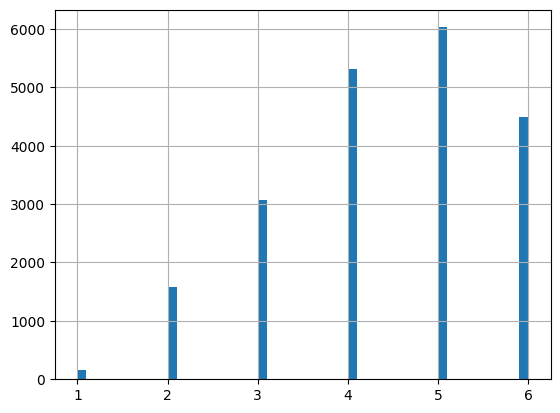

In [343]:
data["income_cat"].hist(bins=50)

In [344]:
split = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
for train_index, test_index in split.split(data, data["income_cat"]):
    strat_train_set = data.loc[train_index]
    strat_test_set = data.loc[test_index]

In [345]:
def income_cat_proportions(data):
    return data["income_cat"].value_counts() / len(data)

# Random Sampling
train_set, test_set = train_test_split(data, test_size=0.2, random_state=42)

compare_props = pd.DataFrame({
    "Overall": income_cat_proportions(data), #Proporsi kategori pada seluruh dataset.
    "Stratified": income_cat_proportions(strat_test_set), #Proporsi kategori pada test set hasil stratified sampling.
    "Random": income_cat_proportions(test_set) #Proporsi kategori pada test set hasil random sampling.
}).sort_index()

compare_props["Rand. %error"] = 100 * compare_props["Random"] / compare_props["Overall"] - 100 #Persentase perbedaan proporsi random terhadap Overall.
compare_props["Strat. %error"] = 100 * compare_props["Stratified"] / compare_props["Overall"] - 100 #Persentase perbedaan proporsi stratified terhadap Overall.

compare_props

,Overall,Stratified,Random,Rand. %error,Strat. %error
income_cat,,,,,
1,0.01,0.01,0.01,3.77,0.63
2,0.08,0.08,0.08,4.18,0.06
3,0.15,0.15,0.15,-0.39,-0.07
4,0.26,0.26,0.27,3.23,0.04
5,0.29,0.29,0.29,0.28,-0.05
6,0.22,0.22,0.21,-5.55,0.02


In [346]:
""" 

| Income Category | Overall  | Stratified | Random   | Rand. % Error | Strat. % Error |
| --------------- | -------- | ---------- | -------- | ------------- | -------------- |
| 1               | 0.007703 | 0.007752   | 0.007994 | 3.773585%     | 0.628931%      |
| 2               | 0.076502 | 0.076550   | 0.079700 | 4.179861%     | 0.063331%      |
| 3               | 0.148595 | 0.148498   | 0.148014 | -0.391262%    | -0.065210%     |
| 4               | 0.257655 | 0.257752   | 0.265988 | 3.234299%     | 0.037608%      |
| 5               | 0.292054 | 0.291909   | 0.292878 | 0.282017%     | -0.049768%     |
| 6               | 0.217490 | 0.217539   | 0.205426 | -5.546892%    | 0.022277%      |

1. Income Category = 1
- Overall: 0.007703 atau sekitar 0,77%.
- Stratified: 0.007752 atau sekitar 0,78%.
- Random: 0.007994 atau sekitar 0,80%.
- Random error: 3.77%.
- Stratified error: 0.63%.
Artinya, proporsi kategori 1 pada hasil stratified sampling lebih mendekati proporsi aslinya dibandingkan random sampling.

2. Income Category = 2
- Overall: 0.076502 atau sekitar 7,65%.
- Stratified: 0.076550 atau sekitar 7,66%.
- Random: 0.079700 atau sekitar 7,97%.
- Random error: 4.18%.
- Stratified error: 0.06%.
Artinya, proporsi kategori 2 pada hasil stratified sampling jauh lebih mendekati proporsi aslinya dibandingkan random sampling.

3. Income Category = 3
- Overall: 0.148595 atau sekitar 14,86%.
- Stratified: 0.148498 atau sekitar 14,85%.
- Random: 0.148014 atau sekitar 14,80%.
- Random error: -0.39%.
- Stratified error: -0.07%.
Artinya, kedua metode menghasilkan proporsi yang cukup dekat dengan distribusi aslinya, tetapi stratified sampling memiliki error yang lebih kecil.

4. Income Category = 4
- Overall: 0.257655 atau sekitar 25,77%.
- Stratified: 0.257752 atau sekitar 25,78%.
- Random: 0.265988 atau sekitar 26,60%.
- Random error: 3.23%.
- Stratified error: 0.04%.
Artinya, proporsi kategori 4 pada hasil stratified sampling jauh lebih mendekati proporsi aslinya dibandingkan random sampling.

5. Income Category = 5
- Overall: 0.292054 atau sekitar 29,21%.
- Stratified: 0.291909 atau sekitar 29,19%.
- Random: 0.292878 atau sekitar 29,29%.
- Random error: 0.28%.
- Stratified error: -0.05%.
Artinya, kedua metode menghasilkan proporsi yang sangat dekat dengan distribusi aslinya, tetapi stratified sampling tetap memiliki error yang lebih kecil.

6. Income Category = 6
- Overall: 0.217490 atau sekitar 21,75%.
- Stratified: 0.217539 atau sekitar 21,75%.
- Random: 0.205426 atau sekitar 20,54%.
- Random error: -5.55%.
- Stratified error: 0.02%.
Artinya, proporsi kategori 6 pada hasil stratified sampling jauh lebih mendekati proporsi aslinya dibandingkan random sampling.

Kesimpulan
Dari keenam kategori tersebut, stratified sampling secara konsisten menghasilkan persentase error yang lebih kecil dibandingkan random sampling. Hal ini menunjukkan bahwa stratified sampling mampu mempertahankan distribusi income_cat pada test set agar lebih mendekati distribusi keseluruhan dataset.

"""

' \n\n| Income Category | Overall  | Stratified | Random   | Rand. % Error | Strat. % Error |\n| --------------- | -------- | ---------- | -------- | ------------- | -------------- |\n| 1               | 0.007703 | 0.007752   | 0.007994 | 3.773585%     | 0.628931%      |\n| 2               | 0.076502 | 0.076550   | 0.079700 | 4.179861%     | 0.063331%      |\n| 3               | 0.148595 | 0.148498   | 0.148014 | -0.391262%    | -0.065210%     |\n| 4               | 0.257655 | 0.257752   | 0.265988 | 3.234299%     | 0.037608%      |\n| 5               | 0.292054 | 0.291909   | 0.292878 | 0.282017%     | -0.049768%     |\n| 6               | 0.217490 | 0.217539   | 0.205426 | -5.546892%    | 0.022277%      |\n\n1. Income Category = 1\n- Overall: 0.007703 atau sekitar 0,77%.\n- Stratified: 0.007752 atau sekitar 0,78%.\n- Random: 0.007994 atau sekitar 0,80%.\n- Random error: 3.77%.\n- Stratified error: 0.63%.\nArtinya, proporsi kategori 1 pada hasil stratified sampling lebih mendekati pro

In [347]:
for i in (strat_train_set, strat_test_set):
    i.drop("income_cat", axis=1, inplace=True)

In [348]:
strat_train_set.head()

,medinc,houseage,averooms,avebedrms,population,aveoccup,latitude,longitude,target
15295,"22,500.00",24,4.09,1.13,610,2.48,33.16,-117.34,"187,500.00"
10539,"63,088.00",6,7.04,1.14,6223,2.64,33.48,-117.70,"340,300.00"
8475,"57,528.00",34,4.62,0.86,757,3.28,33.91,-118.32,"180,500.00"
14190,"28,372.00",26,5.96,1.18,2822,4.05,32.71,-117.07,"123,400.00"
6111,"26,619.00",25,4.09,1.14,2868,3.81,34.13,-117.90,"117,600.00"


In [349]:
strat_test_set.head()

,medinc,houseage,averooms,avebedrms,population,aveoccup,latitude,longitude,target
11284,"63,700.00",35,6.13,0.93,658,3.03,33.78,-117.96,"229,200.00"
3474,"66,458.00",31,5.97,0.99,1957,3.33,34.28,-118.49,"285,500.00"
18910,"16,368.00",28,4.36,1.12,1375,1.95,38.13,-122.26,"91,200.00"
8706,"53,990.00",34,5.35,1.00,965,2.93,33.83,-118.34,"358,500.00"
3917,"26,250.00",32,4.14,1.09,1961,3.10,34.19,-118.53,"192,300.00"


# EDA

In [350]:
df = strat_train_set.copy()

## Univariate EDA

In [351]:
df.head()

,medinc,houseage,averooms,avebedrms,population,aveoccup,latitude,longitude,target
15295,"22,500.00",24,4.09,1.13,610,2.48,33.16,-117.34,"187,500.00"
10539,"63,088.00",6,7.04,1.14,6223,2.64,33.48,-117.70,"340,300.00"
8475,"57,528.00",34,4.62,0.86,757,3.28,33.91,-118.32,"180,500.00"
14190,"28,372.00",26,5.96,1.18,2822,4.05,32.71,-117.07,"123,400.00"
6111,"26,619.00",25,4.09,1.14,2868,3.81,34.13,-117.90,"117,600.00"


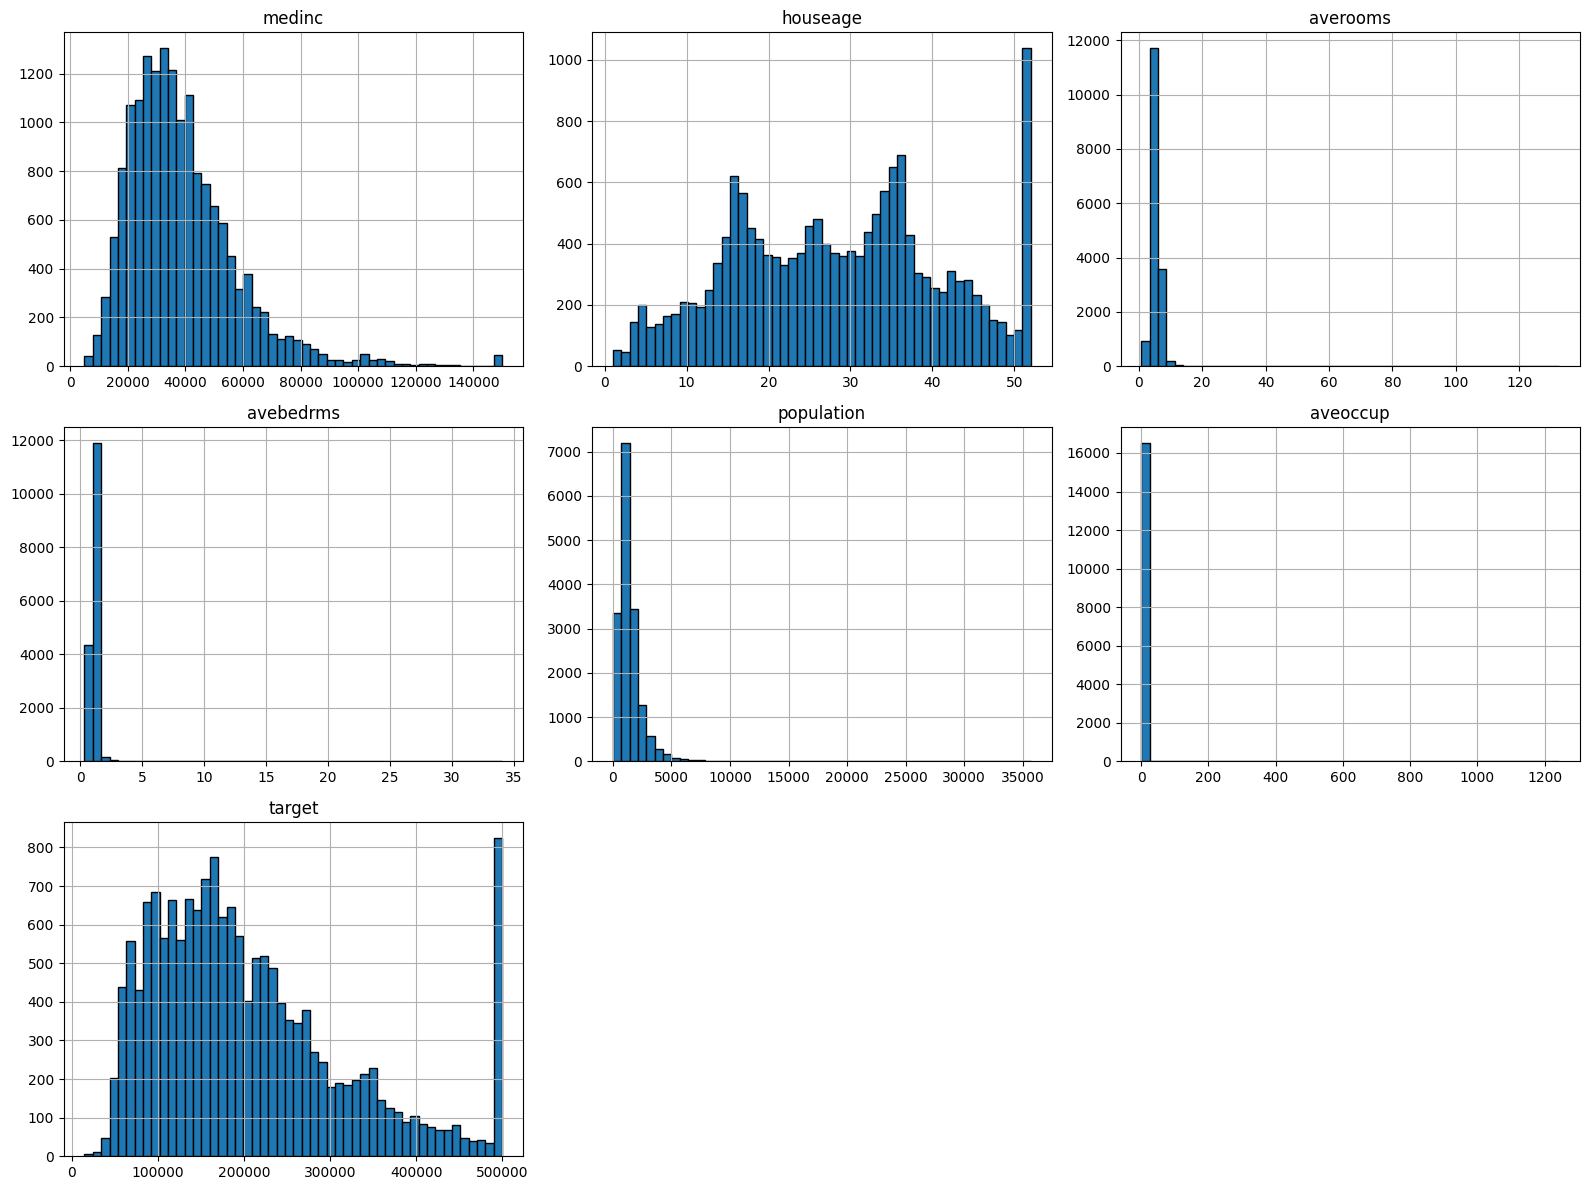

' \n- Secara distribusi memang tidak ada perbedaan dengan data sebelum di split\n- Nilai capped yang ada itu juga masih sama dengan data sebelumnya\n'

In [352]:
df_dist = df[
    ["medinc", "houseage", "averooms", "avebedrms",
     "population", "aveoccup", "target"]
]

df_dist.hist(
    bins=50,
    figsize=(16, 12),
    layout=(3, 3),
    edgecolor="black"
)

plt.tight_layout()
plt.show()

""" 
- Secara distribusi memang tidak ada perbedaan dengan data sebelum di split
- Nilai capped yang ada itu juga masih sama dengan data sebelumnya
"""

Text(0, 0.5, 'Values')

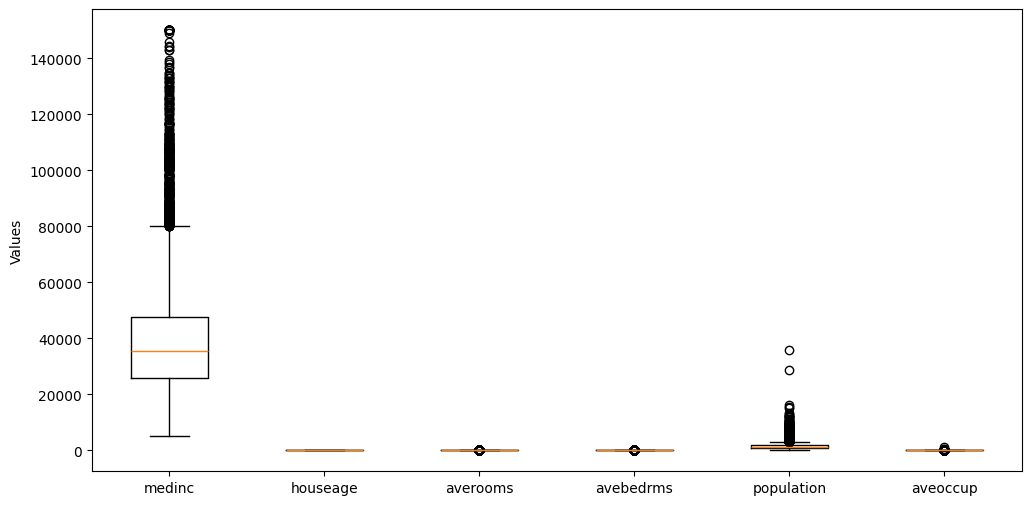

In [353]:
features = [
    "medinc", "houseage", "averooms",
    "avebedrms", "population", "aveoccup"
]

plt.figure(figsize=(12, 6))

plt.boxplot(
    [df_dist[col] for col in features],
    tick_labels=features
)

plt.ylabel('Values')

## Bivariate EDA

In [354]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 16512 entries, 15295 to 17975
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   medinc      16512 non-null  float64
 1   houseage    16512 non-null  int64  
 2   averooms    16512 non-null  float64
 3   avebedrms   16512 non-null  float64
 4   population  16512 non-null  int64  
 5   aveoccup    16512 non-null  float64
 6   latitude    16512 non-null  float64
 7   longitude   16512 non-null  float64
 8   target      16512 non-null  float64
dtypes: float64(7), int64(2)
memory usage: 1.3 MB


' \n- Secara korelasi ada beberapa fitur yang memiliki nilai korelasi tinggi dengan fitur target yakni averooms, houseage, medinc\n- Selain dengan fitur target, kolom lain juga ada yang berkorelasi contohnya avebedrms dengan averooms, medinc dengan averooms\n'

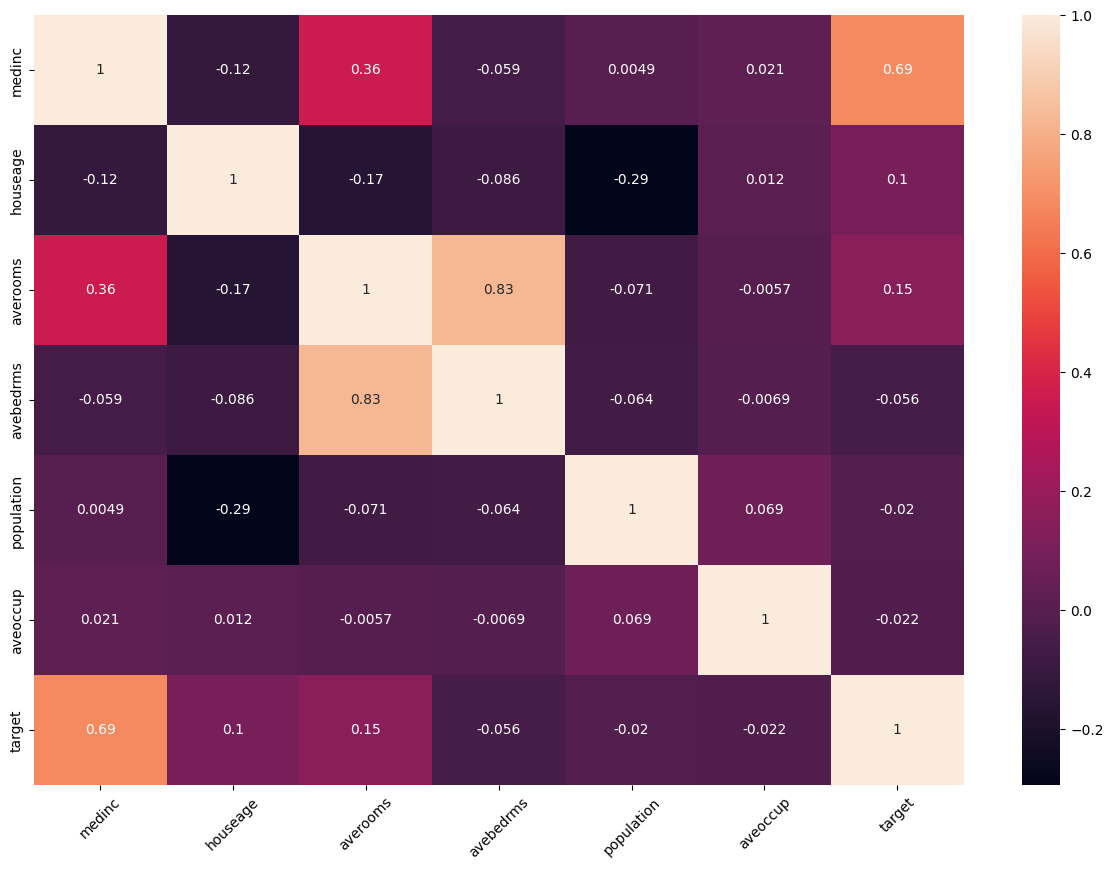

In [355]:
plt.figure(figsize=(15, 10))
sns.heatmap(df[df_dist.columns].corr(), annot=True)
plt.xticks(rotation=45)

""" 
- Secara korelasi ada beberapa fitur yang memiliki nilai korelasi tinggi dengan fitur target yakni averooms, houseage, medinc
- Selain dengan fitur target, kolom lain juga ada yang berkorelasi contohnya avebedrms dengan averooms, medinc dengan averooms
"""

In [356]:
""" 
Findings
1. MedInc memiliki korelasi paling kuat dengan target (0.69).
- Semakin tinggi median income suatu wilayah, cenderung semakin tinggi pula median harga rumahnya.
- Ini menunjukkan bahwa medinc berpotensi menjadi salah satu fitur paling informatif dalam memprediksi harga rumah.
- Hubungannya positif, tetapi tidak berarti setiap kenaikan income selalu diikuti kenaikan harga rumah.

2. AveRooms memiliki korelasi positif lemah dengan target (0.15).
- Wilayah dengan rata-rata jumlah ruangan lebih banyak cenderung memiliki harga rumah sedikit lebih tinggi.
- Namun, kekuatan hubungannya relatif lemah.
- Jumlah ruangan saja tampaknya belum cukup menjelaskan variasi harga rumah.

3. HouseAge memiliki korelasi positif sangat lemah dengan target (0.10).
- Terdapat kecenderungan bahwa wilayah dengan usia rumah lebih tinggi memiliki harga rumah sedikit lebih tinggi.
- Namun, hubungannya sangat lemah sehingga houseage kemungkinan tidak cukup informatif jika digunakan sendirian.

4. AveBedrms, Population, dan AveOccup memiliki korelasi negatif yang sangat lemah dengan target.
- Nilai korelasinya mendekati nol.
- Artinya, tidak terlihat hubungan linear yang berarti antara ketiga fitur tersebut dengan harga rumah.
- Namun, bukan berarti fitur-fitur tersebut tidak memiliki informasi prediktif. Bisa saja terdapat hubungan non-linear atau interaksi dengan fitur lainnya.


5. AveRooms dan AveBedrms memiliki korelasi sangat kuat (0.83).
- Kedua fitur memiliki hubungan linear positif yang sangat kuat.
- Wilayah dengan rata-rata jumlah ruangan lebih banyak cenderung memiliki rata-rata jumlah kamar tidur lebih banyak.
- Ada kemungkinan kedua fitur membawa sebagian informasi yang serupa.
- Hal ini perlu diperhatikan ketika melakukan feature selection atau membangun model linear.

6. MedInc dan AveRooms memiliki korelasi positif sedang (0.36).
- Wilayah dengan median income lebih tinggi cenderung memiliki rata-rata jumlah ruangan lebih banyak.
- Ini menunjukkan adanya hubungan antara kondisi ekonomi wilayah dengan karakteristik hunian.

7. HouseAge dan Population memiliki korelasi negatif (-0.29).
- Wilayah dengan rata-rata usia rumah lebih tinggi cenderung memiliki jumlah populasi lebih rendah.
- Namun, hubungan ini relatif lemah sehingga tidak bisa dijadikan kesimpulan bahwa rumah yang lebih tua menyebabkan populasi lebih sedikit.

8. Sebagian besar kombinasi fitur lainnya memiliki korelasi mendekati nol.
- Ini menunjukkan bahwa sebagian besar fitur tidak memiliki hubungan linear yang kuat satu sama lain.
- Namun, tetap perlu diperhatikan bahwa korelasi Pearson hanya mengukur hubungan linear.
"""

' \nFindings\n1. MedInc memiliki korelasi paling kuat dengan target (0.69).\n- Semakin tinggi median income suatu wilayah, cenderung semakin tinggi pula median harga rumahnya.\n- Ini menunjukkan bahwa medinc berpotensi menjadi salah satu fitur paling informatif dalam memprediksi harga rumah.\n- Hubungannya positif, tetapi tidak berarti setiap kenaikan income selalu diikuti kenaikan harga rumah.\n\n2. AveRooms memiliki korelasi positif lemah dengan target (0.15).\n- Wilayah dengan rata-rata jumlah ruangan lebih banyak cenderung memiliki harga rumah sedikit lebih tinggi.\n- Namun, kekuatan hubungannya relatif lemah.\n- Jumlah ruangan saja tampaknya belum cukup menjelaskan variasi harga rumah.\n\n3. HouseAge memiliki korelasi positif sangat lemah dengan target (0.10).\n- Terdapat kecenderungan bahwa wilayah dengan usia rumah lebih tinggi memiliki harga rumah sedikit lebih tinggi.\n- Namun, hubungannya sangat lemah sehingga houseage kemungkinan tidak cukup informatif jika digunakan sendiri

<Figure size 800x600 with 0 Axes>

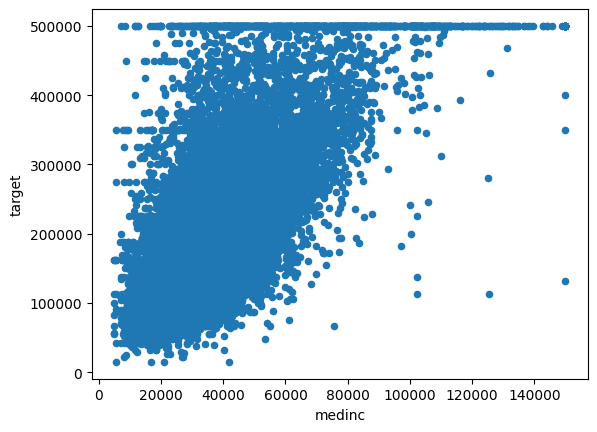

'\n- Nilai dari fitur target itu sudah di capped, artinya nilai diatas 500000 itu dikelompokkan atau masuk ke dalam 500000\n- Hubungan antara medinc dengan target ini linear keatas, semakin besar median income berarti harga rumah juga besar\n- Median income < 80000 itu punya rumah dengan harga hingga 500000\n'

In [357]:
def plot_num_num(col_1, col_2):
    plt.figure(figsize=(8, 6))
    df.plot(kind='scatter', x=col_1, y=col_2)
    plt.show()

plot_num_num('medinc', 'target')

"""
- Nilai dari fitur target itu sudah di capped, artinya nilai diatas 500000 itu dikelompokkan atau masuk ke dalam 500000
- Hubungan antara medinc dengan target ini linear keatas, semakin besar median income berarti harga rumah juga besar
- Median income < 80000 itu punya rumah dengan harga hingga 500000
"""

<Figure size 800x600 with 0 Axes>

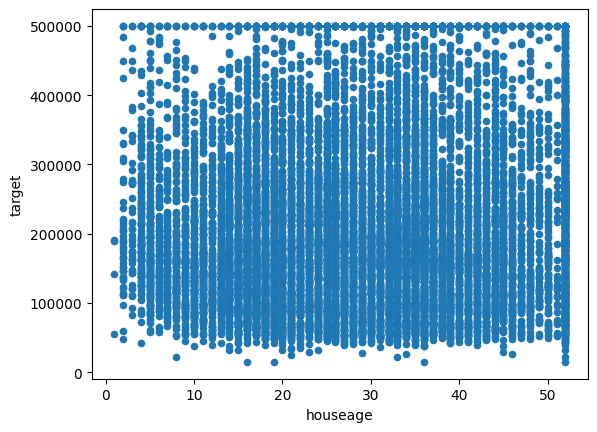

' \n- Data umur rumah atau houseage itu sepertinya kategorical\n- Data house age juga dilakukan capped data\n'

In [358]:
plot_num_num('houseage', 'target')

""" 
- Data umur rumah atau houseage itu sepertinya kategorical
- Data house age juga dilakukan capped data
"""

<Figure size 800x600 with 0 Axes>

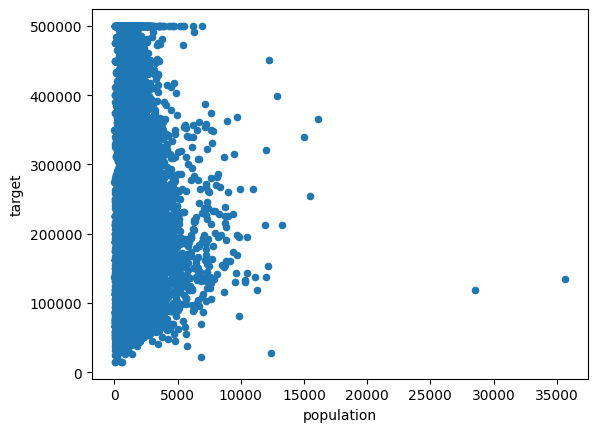

'\n- Population tersebar paling banyak dibawah 5000\n'

In [359]:
plot_num_num('population', 'target')

"""
- Population tersebar paling banyak dibawah 5000
"""

<Figure size 800x600 with 0 Axes>

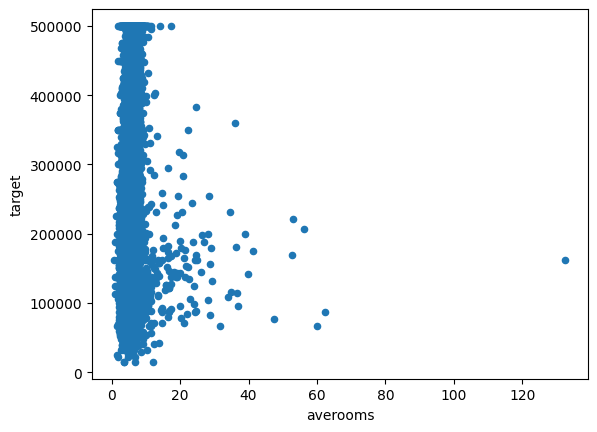

' \n- Data menunjukkan rata-rata kamar rumah itu paling banyak < 10\n'

In [360]:
plot_num_num('averooms', 'target')

""" 
- Data menunjukkan rata-rata kamar rumah itu paling banyak < 10
"""

<Figure size 800x600 with 0 Axes>

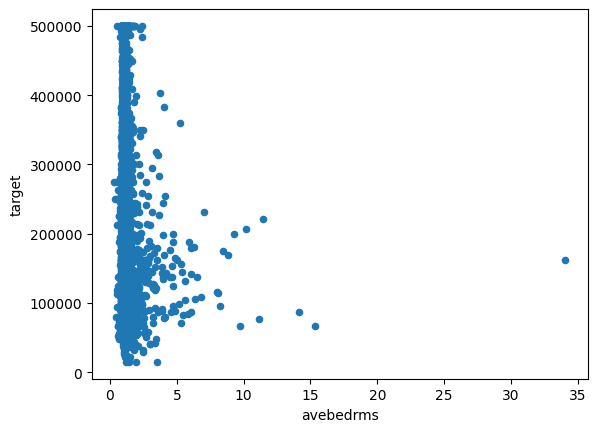

'\n- Data menunjukkan kalau rata-rata kamar tidur paling banyak dibawah 3 bahkan harga rumah yang tertinggi\n'

In [361]:
plot_num_num('avebedrms', 'target')

"""
- Data menunjukkan kalau rata-rata kamar tidur paling banyak dibawah 3 bahkan harga rumah yang tertinggi
"""

<Figure size 800x600 with 0 Axes>

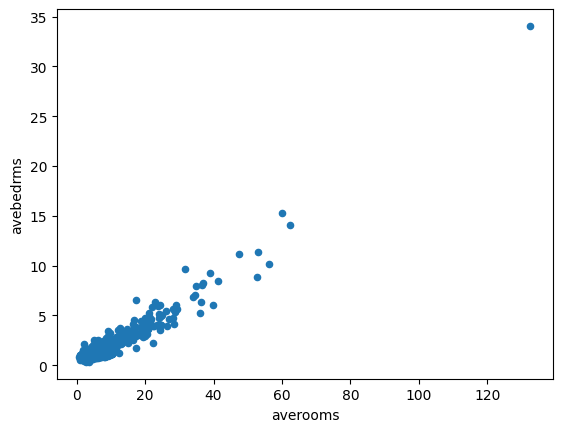

' \n- Hubungan antara rata-rata kamar dengan rata-rata kamar tidur itu linear\n- Rumah yang memiliki kamar dibawah 20 kamar relatif memiliki kamar tidur dibawah 5\n'

In [362]:
plot_num_num('averooms', 'avebedrms')

""" 
- Hubungan antara rata-rata kamar dengan rata-rata kamar tidur itu linear
- Rumah yang memiliki kamar dibawah 20 kamar relatif memiliki kamar tidur dibawah 5
"""

<Figure size 800x600 with 0 Axes>

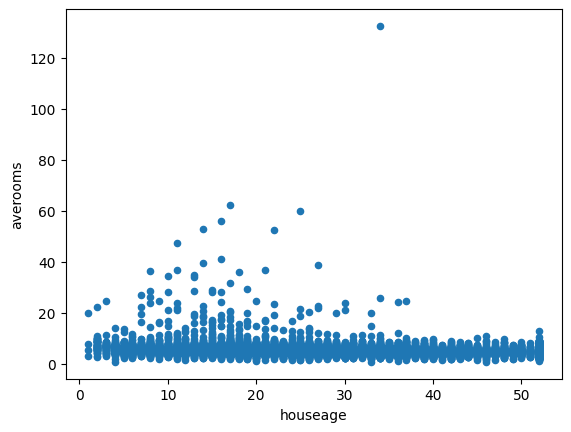

In [363]:
plot_num_num('houseage', 'averooms')

<Figure size 800x600 with 0 Axes>

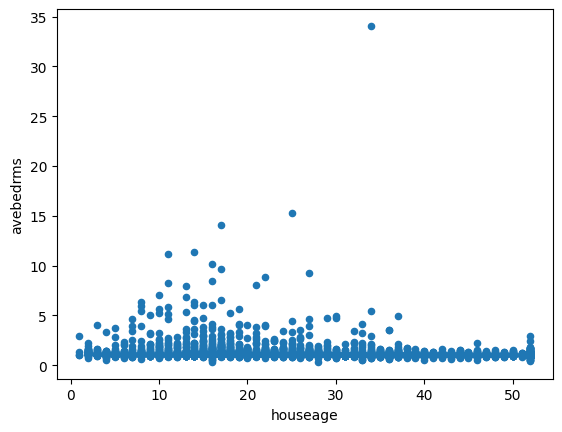

In [364]:
plot_num_num('houseage', 'avebedrms')

<Figure size 800x600 with 0 Axes>

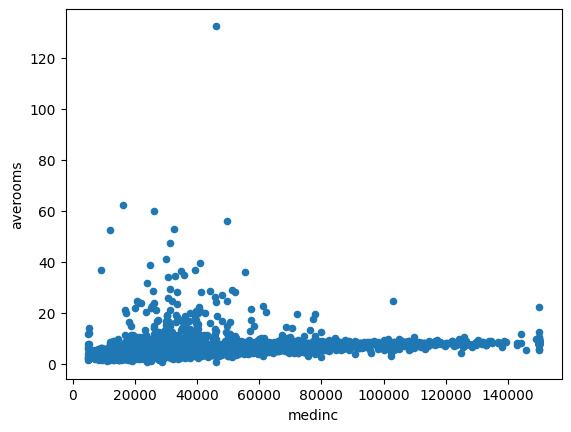

' \n- Di semua median income, rata-rata kamarnya berjumlah kurang dari 20\n'

In [365]:
plot_num_num('medinc', 'averooms')

""" 
- Di semua median income, rata-rata kamarnya berjumlah kurang dari 20
"""

'\n- Ini peta sebaran data rumah di California\n- Kawasan di pinggir pantai memiliki kepadatan persebaran data yang tinggi\n'

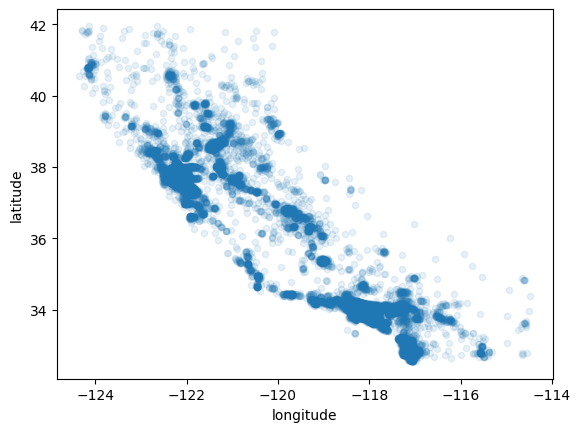

In [366]:
df.plot(kind='scatter', x='longitude', y='latitude', alpha=0.1) # alpha membantu kita melihat kepadatan persebaran data (data density) pada scatter plot

"""
- Ini peta sebaran data rumah di California
- Kawasan di pinggir pantai memiliki kepadatan persebaran data yang tinggi
"""

## Multivariate EDA

'\n- Orang yang memiliki median income \n'

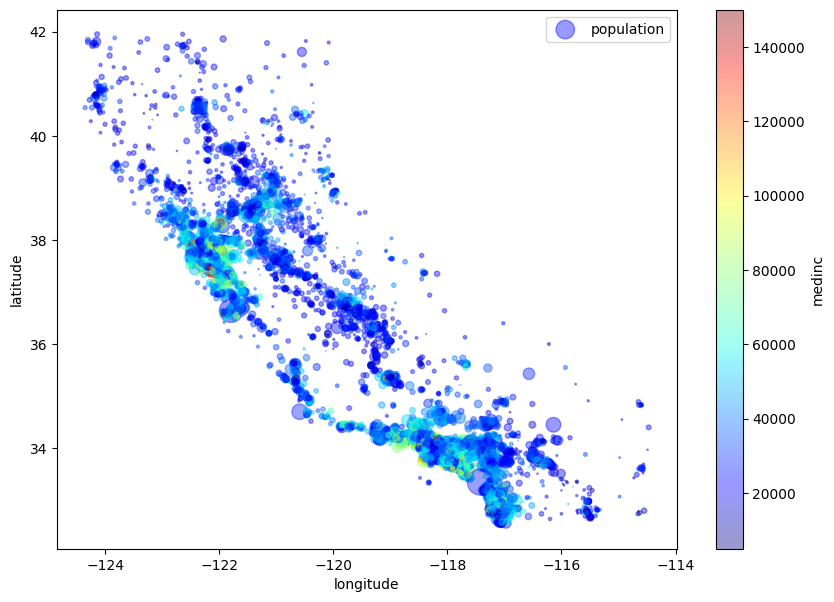

In [367]:
df.plot(
    kind='scatter',
    x='longitude',
    y='latitude',
    alpha=0.4,
    s=df['population'] / 100,
    label='population',
    figsize=(10, 7),
    c='medinc',
    cmap=plt.get_cmap('jet'),
    colorbar=True,
    sharex=False
)


plt.legend()

"""
- Orang yang memiliki median income 
"""

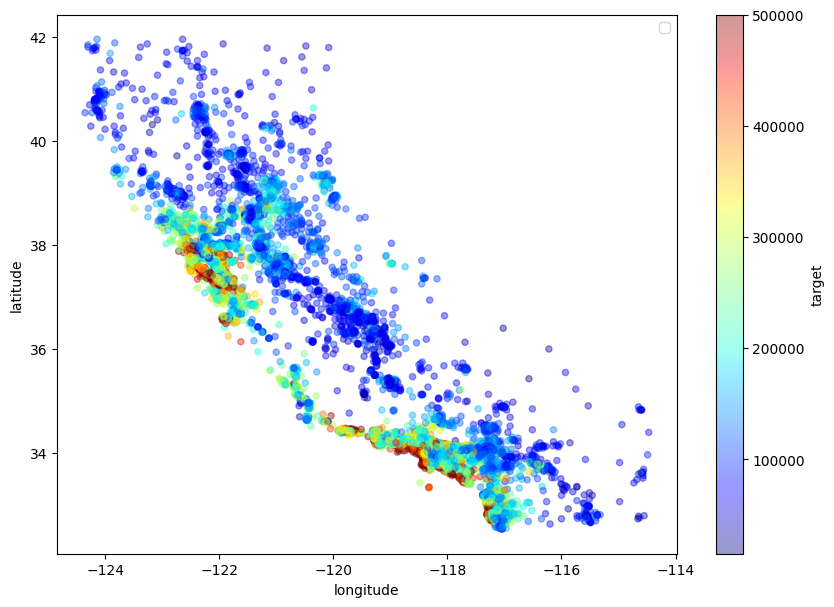

In [368]:
df.plot(
    kind='scatter',
    x='longitude',
    y='latitude',
    alpha=0.4,
    figsize=(10, 7),
    c='target',
    cmap=plt.get_cmap('jet'),
    colorbar=True,
    sharex=False
)


plt.legend()

### Geographic Grouping

In [369]:
df['lat_group'] = pd.cut(df['latitude'], bins=5)
df['lon_group'] = pd.cut(df['longitude'], bins=5)

geo_analysis = (
    df.groupby(['lat_group', 'lon_group'], observed=True)
    .agg(
        avg_income=("medinc", 'mean'),
        avg_house_value=("target", 'mean'),
        avg_house_age=('houseage', 'mean'),
        avg_population=('population', 'mean'),
        total_observations=('target', 'count'),
        avg_target=('target', 'mean')
    )
)

geo_analysis

avg_income  ...  avg_target
lat_group        lon_group                         ...            
(32.531, 34.422] (-120.398, -118.422]   48,983.71  ...  301,233.09
                 (-118.422, -116.446]   39,035.65  ...  214,898.74
                 (-116.446, -114.47]    27,813.96  ...   98,827.37
(34.422, 36.304] (-122.374, -120.398]   33,380.98  ...  186,282.20
                 (-120.398, -118.422]   31,208.96  ...  131,026.95
                 (-118.422, -116.446]   33,808.54  ...  116,738.43
                 (-116.446, -114.47]    21,818.33  ...   64,533.33
(36.304, 38.186] (-124.36, -122.374]    43,588.87  ...  332,801.80
                 (-122.374, -120.398]   42,736.69  ...  227,765.19
                 (-120.398, -118.422]   28,751.26  ...   89,124.96
                 (-118.422, -116.446]   23,567.88  ...   89,637.38
(38.186, 40.068] (-124.36, -122.374]    32,885.59  ...  171,978.91
                 (-122.374, -120.398]   32,965.65  ...  131,609.83
                 (-120.398, -118.422]   31,971.77  ...  135,262.75
(40.068, 41.95]  (-124.36, -122.374]    24,367.34  ...   85,718.91
                 (-122.374, -120.398]   26,332.73  ...   82,722.40
                 (-120.398, -118.422]   23,096.50  ...   82,033.33

[17 rows x 6 columns]

Text(120.72222222222221, 0.5, 'Latitude')

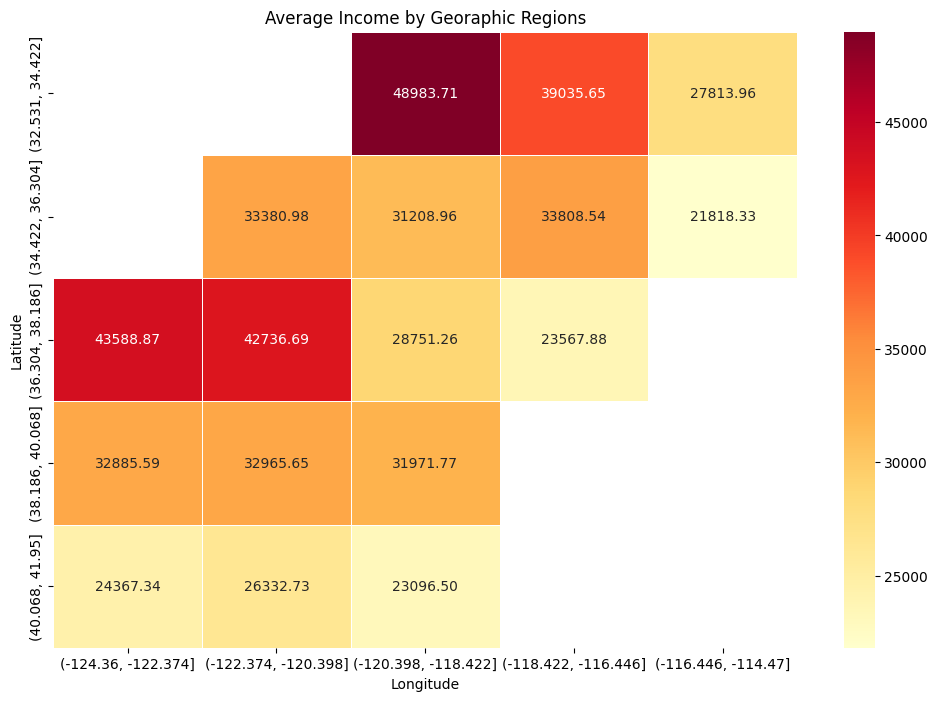

In [370]:
income_pivot = geo_analysis['avg_income'].unstack()

plt.figure(figsize=(12, 8))

sns.heatmap(
    income_pivot,
    annot=True,
    fmt='.2f',
    cmap='YlOrRd',
    linewidths=0.5
)

plt.title('Average Income by Georaphic Regions')
plt.xlabel('Longitude')
plt.ylabel('Latitude')

Text(120.72222222222221, 0.5, 'Latitude')

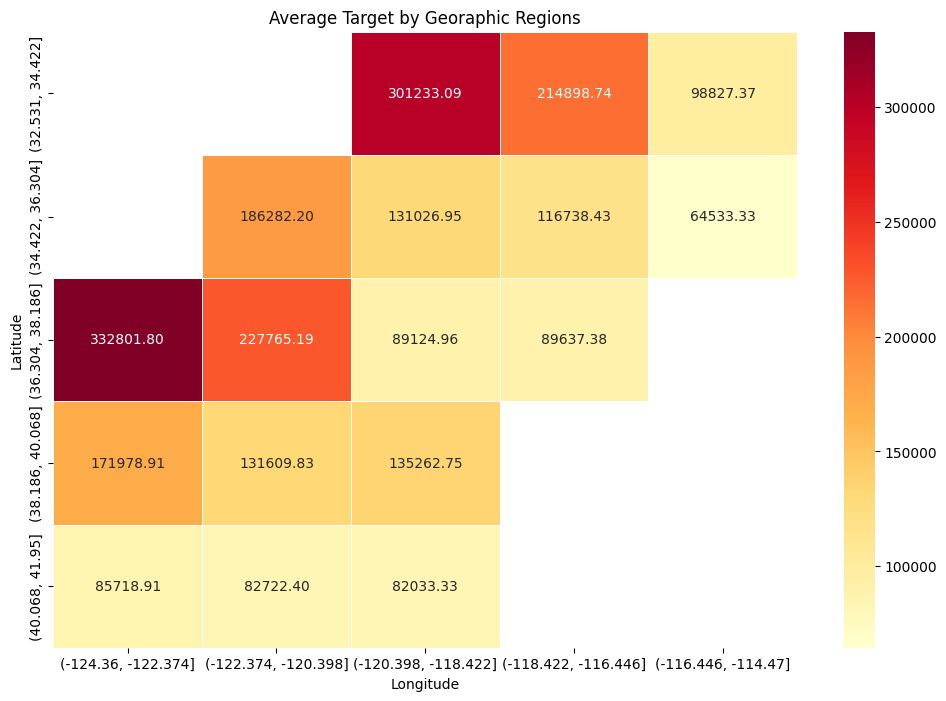

In [371]:
income_pivot = geo_analysis['avg_target'].unstack()

plt.figure(figsize=(12, 8))

sns.heatmap(
    income_pivot,
    annot=True,
    fmt='.2f',
    cmap='YlOrRd',
    linewidths=0.5
)

plt.title('Average Target by Georaphic Regions')
plt.xlabel('Longitude')
plt.ylabel('Latitude')

In [372]:
filter_df_1 = df[
    (df['latitude'].between(32.531, 34.422)) &
    (df['longitude'].between(-120.398, -118.422))
]

filter_df_2 = df[
    (df['latitude'].between(36.304, 38.186)) &
    (df['longitude'].between(-124.36, -122.374))
]

filter_df_3 = df[
    (df['latitude'].between(36.304, 38.186)) &
    (df['longitude'].between(-122.374, -120.398))
]

filter_df_4 = df[
    (df['latitude'].between(32.531, 34.422)) &
    (df['longitude'].between(-118.422, -116.466))
]

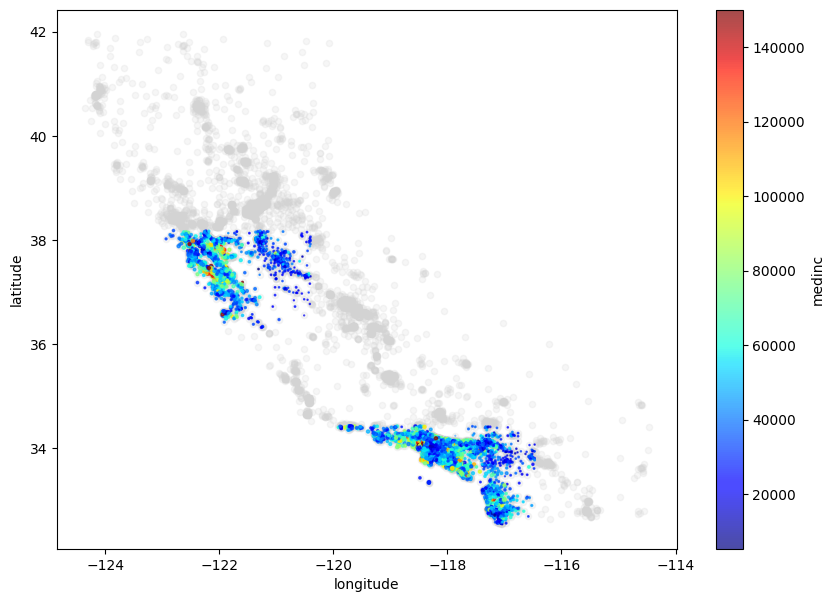

In [373]:
fig, ax = plt.subplots(figsize=(10, 7))

strat_train_set.plot(
    kind="scatter",
    x="longitude",
    y="latitude",
    alpha=0.2,
    color="lightgray",
    ax=ax
)

filter_df_1.plot(
    kind="scatter",
    x="longitude",
    y="latitude",
    alpha=0.7,
    c="medinc",
    s=filter_df_1['target'] / 100000,
    cmap="jet",
    colorbar=True,
    ax=ax
)

filter_df_2.plot(
    kind="scatter",
    x="longitude",
    y="latitude",
    alpha=0.7,
    c="medinc",
    s=filter_df_2['target'] / 100000,
    cmap="jet",
    colorbar=False,
    ax=ax
)

filter_df_3.plot(
    kind="scatter",
    x="longitude",
    y="latitude",
    alpha=0.7,
    c="medinc",
    s=filter_df_3['target'] / 100000,
    cmap="jet",
    colorbar=False,
    ax=ax
)

filter_df_4.plot(
    kind="scatter",
    x="longitude",
    y="latitude",
    alpha=0.7,
    c="medinc",
    s=filter_df_4['target'] / 100000,
    cmap="jet",
    colorbar=False,
    ax=ax
)

plt.show()

<Axes: xlabel='longitude', ylabel='latitude'>

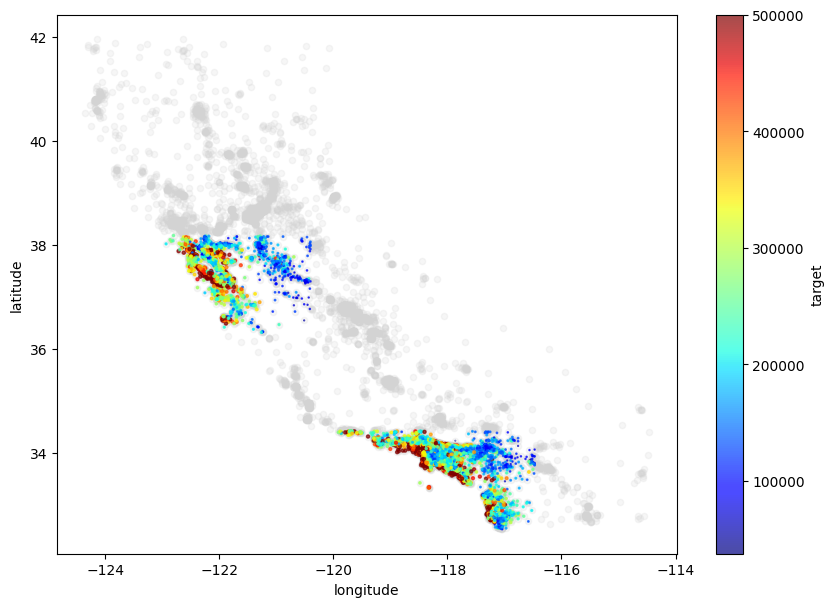

In [374]:
fig, ax = plt.subplots(figsize=(10, 7))

strat_train_set.plot(
    kind="scatter",
    x="longitude",
    y="latitude",
    alpha=0.2,
    color="lightgray",
    ax=ax
)

filter_df_1.plot(
    kind="scatter",
    x="longitude",
    y="latitude",
    alpha=0.7,
    c="target",
    s=filter_df_1['target'] / 100000,
    cmap="jet",
    colorbar=True,
    ax=ax
)

filter_df_2.plot(
    kind="scatter",
    x="longitude",
    y="latitude",
    alpha=0.7,
    c="target",
    s=filter_df_2['target'] / 100000,
    cmap="jet",
    colorbar=False,
    ax=ax
)

filter_df_3.plot(
    kind="scatter",
    x="longitude",
    y="latitude",
    alpha=0.7,
    c="target",
    s=filter_df_3['target'] / 100000,
    cmap="jet",
    colorbar=False,
    ax=ax
)

filter_df_4.plot(
    kind="scatter",
    x="longitude",
    y="latitude",
    alpha=0.7,
    c="target",
    s=filter_df_4['target'] / 100000,
    cmap="jet",
    colorbar=False,
    ax=ax
)

## EDA Summary

- Untuk hasil Univariate menggunakan beberapa kolom/fitur yang dipilih, menunjukkan secara distribusi sama distribusinya dengan data sebelum di split
- Terdapat beberapa kolom yang skewed right, jika hasil dari training kurang baik maka bisa dilakukan transformasi seperti log-transformation agar mengurangi skewness
- Terlihat ada beberapa kolom/fitur yang nilai datanya itu di capped seperti di kolom medinc, houseage, dan target
- Untuk hasil dari Bivariate EDA, ada beberapa fitur yang memiliki korelasi yang cukup tinggi dengan kolom/fitur target yakni averooms, houseage, medinc. Selain itu antar kolom juga ada yang memiliki korelasi tinggi yakni avebedrms dengan averooms, medinc dengan averooms
- Terdapat hubungan linear antara fitur medinc dengan target, ada hubungan linear juga antara averooms dan avebedrms
- Fitur averooms, houseage, dan avebedrms itu kolom dengan tipe data kategorikal, ini terlihat dari visualisasi yang vertikal jika dibandingkan dengan fitur target 
- Kepadatan penduduk terjadi di sekitar wilayah pesisir pantai California
- Harga rumah di wilayah pesisir pantai itu bervariasi dan banyak rumah yang harganya lebih tinggi dibandingkan dengan wilayah lain 
- Jika melakukan grouping wilayah di California dan menghitung nilai mean dari income. Wilayah di pesisir pantai memiliki nilai mean dari income yang tinggi. 
- Dan pernyataan sebelumnya juga sejalan dengan harga rumah di wilayah pesisir pantai yang tinggi, berarti wilayah dengan harga rumah tinggi itu juga memiliki income yang tinggi juga

# Data Cleaning

## Outliers

Text(0, 0.5, 'Values')

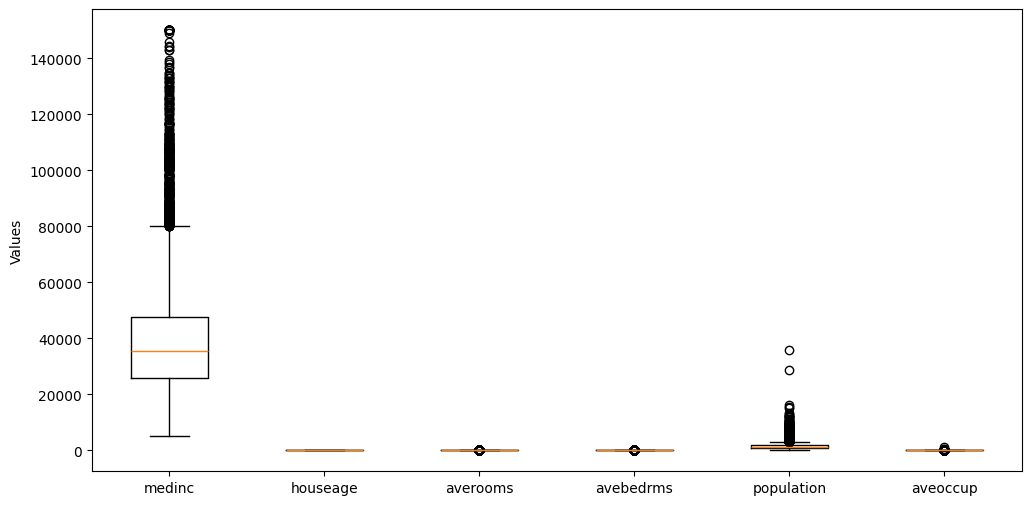

In [375]:
features = [
    "medinc", "houseage", "averooms",
    "avebedrms", "population", "aveoccup"
]


plt.figure(figsize=(12, 6))

plt.boxplot(
    [strat_train_set[col] for col in features],
    tick_labels=features
)

plt.ylabel('Values')

In [376]:
# Count outlier per columns

def count_outlier_per_cols(data, name_col):

    Q1 = data[name_col].quantile(0.25)
    Q3 = data[name_col].quantile(0.75)

    IQR = Q3 - Q1 

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR 

    mask = (data[name_col] < lower) | (data[name_col] > upper)
    outlier_mask = mask

    return outlier_mask.sum()


features = [
    "medinc", "houseage", "averooms",
    "avebedrms", "population", "aveoccup"
]

outlier_summary = pd.DataFrame({
    "outlier_count": {
        col: count_outlier_per_cols(strat_train_set, col)
        for col in features
    }
})

outlier_summary

,outlier_count
medinc,557
houseage,0
averooms,409
avebedrms,1156
population,968
aveoccup,551


In [377]:
outlier_mask = pd.Series(False, index=strat_train_set.index)

for col in strat_train_set.columns:
    Q1 = strat_train_set[col].quantile(0.25)
    Q3 = strat_train_set[col].quantile(0.75)

    IQR = Q3 - Q1 

    lower = Q1 - 1.5 * IQR 
    upper = Q3 + 1.5 * IQR 

    mask = (strat_train_set[col] < lower) | (strat_train_set[col] > upper)
    outlier_mask = outlier_mask | mask # sebuah baris akan ditandai sebagai outlier apabila setidaknya ada satu kolom yang memiliki nilai outlier.

outlier_rows = strat_train_set[outlier_mask]
outlier_rows

,medinc,houseage,averooms,avebedrms,population,aveoccup,latitude,longitude,target
10539,"63,088.00",6,7.04,1.14,6223,2.64,33.48,-117.70,"340,300.00"
8475,"57,528.00",34,4.62,0.86,757,3.28,33.91,-118.32,"180,500.00"
19792,"16,250.00",25,6.34,1.70,301,2.49,40.77,-123.28,"79,200.00"
17184,"45,625.00",21,4.67,1.19,801,3.09,37.50,-122.49,"500,000.00"
4281,"25,556.00",27,1.88,0.88,332,2.96,34.09,-118.32,"175,000.00"
...,...,...,...,...,...,...,...,...,...
6345,"17,206.00",27,4.51,1.11,469,4.84,34.05,-117.75,"107,500.00"
14329,"7,685.00",39,2.75,1.60,206,1.82,32.71,-117.17,"187,500.00"
7840,"39,333.00",37,4.36,0.84,1237,3.60,33.91,-118.17,"162,300.00"
6892,"36,512.00",18,4.37,1.07,3842,3.01,34.04,-118.09,"168,500.00"


In [378]:
# Drop outlier -> One Time Filtering

mask = pd.Series(True, index=strat_train_set.index)

for col in features:
    Q1 = strat_train_set[col].quantile(0.25)
    Q3 = strat_train_set[col].quantile(0.75)

    IQR = Q3 - Q1 

    lower = Q1 - 1.5 * IQR 
    upper = Q3 + 1.5 * IQR 

    mask &= (strat_train_set[col] >= lower) & (strat_train_set[col] <= upper)

train_set = strat_train_set[mask]
train_set

,medinc,houseage,averooms,avebedrms,population,aveoccup,latitude,longitude,target
15295,"22,500.00",24,4.09,1.13,610,2.48,33.16,-117.34,"187,500.00"
14190,"28,372.00",26,5.96,1.18,2822,4.05,32.71,-117.07,"123,400.00"
6111,"26,619.00",25,4.09,1.14,2868,3.81,34.13,-117.90,"117,600.00"
10862,"50,956.00",21,5.81,1.04,2266,3.61,33.70,-117.87,"246,000.00"
1020,"38,523.00",25,5.50,1.18,900,2.54,37.66,-121.78,"193,000.00"
...,...,...,...,...,...,...,...,...,...
3947,"33,534.00",41,4.32,0.93,778,3.18,34.21,-118.61,"180,500.00"
15505,"53,905.00",12,7.09,1.14,1958,2.73,33.08,-117.26,"299,600.00"
11428,"57,117.00",16,5.77,1.04,986,2.34,33.69,-117.98,"247,200.00"
19822,"20,857.00",22,5.13,1.07,1185,4.37,36.44,-119.48,"49,200.00"


# Feature Engineering

In [379]:
X_train = train_set.drop(columns="target")
y_train = train_set['target']

X_test = strat_test_set.drop(columns='target')
y_test = strat_test_set['target']

In [380]:
## Menghitung proporsi kamar tidur dibandingkan keseluruhan ruangan

X_train['bedrooms_per_room'] = X_train['avebedrms'] / X_train['averooms']
X_test['bedrooms_per_room'] = X_test['avebedrms'] / X_test['averooms']

## Estimasi jumlah rumah tangga
X_train['estimated_households'] = X_train['population'] / X_train['aveoccup']
X_test['estimated_households'] = X_test['population'] / X_test['aveoccup']

### Estimasi total rooms
X_train['estimated_total_rooms'] = (X_train['averooms'] * X_train['estimated_households'])
X_test['estimated_total_rooms'] = (X_test['averooms'] * X_test['estimated_households'])

### Estimasi total bedrooms
X_train['estimated_total_bedrooms'] = (X_train['avebedrms'] * X_train['estimated_households'])
X_test['estimated_total_bedrooms'] = (X_test['avebedrms'] * X_test['estimated_households'])



# Feature Selection

In [381]:
selector = SelectKBest(score_func=f_regression, k=5)
selector.fit_transform(X_train, y_train)

""" 
- Menggunakan X_train & y_train karena pemilihan fitur mempertimbangkan hubungan antar fitur dengan target
- Kenapa menggunakan y_train? karena f_regression menghitung hubungan linear setiap fitur dengan target
"""

print('Score tiap fitur:', selector.scores_)
print('Fitur Terpilih:', X_train.columns[selector.get_support()])

Score tiap fitur: [8647.19313746  208.05117588  885.18951629   28.48456634   13.49266614
 1624.96090669  281.27973665   27.62401881  445.44624647  191.89418758
  521.61565046  169.7265626 ]
Fitur Terpilih: Index(['medinc', 'averooms', 'aveoccup', 'bedrooms_per_room',
       'estimated_total_rooms'],
      dtype='object')


In [382]:
selector = VarianceThreshold(threshold=2)
selector.fit_transform(X_train)

""" 
- Hanya menggunakan X_train karena pemilihan fitur tidak mempertimbangkan target
- Kenapa tidak menggunakan y_train? karena metode ini hanya menghitung variance setiap fitur
"""

pd.DataFrame({
    "nama_fitur": X_train.columns,
    "score": selector.variances_
}).sort_values(by='score', ascending=False).reset_index(drop=True)

# 5 Fitur terpilih: medinc, estimated_total_rooms, population, estimated_total_bedrooms, estimated_households

,nama_fitur,score
0,medinc,"218,443,771.26"
1,estimated_total_rooms,"1,532,267.50"
2,population,"393,039.69"
3,estimated_total_bedrooms,"66,872.99"
4,estimated_households,"56,882.53"
5,houseage,150.82
6,latitude,4.52
7,longitude,3.98
8,averooms,1.11
9,aveoccup,0.40


In [383]:
lasso = Lasso(alpha=0.1)
lasso.fit(X_train, y_train)
print('Koefisien:', lasso.coef_)

selected_features = X_train.columns[lasso.coef_ != 0]
print('Fitur Terplih:', selected_features)

# 5 Fitur terpilih: medinc, houseage, averooms, avebedrms, population

Koefisien: [ 4.83901389e+00  1.38696434e+03  1.27664691e+04  4.73507963e+04
 -2.36271999e+01 -3.08113060e+04 -3.87407733e+04 -3.83874930e+04
  5.88529290e+05  7.71359281e+01  4.44642886e-01  5.86224463e+00]
Fitur Terplih: Index(['medinc', 'houseage', 'averooms', 'avebedrms', 'population', 'aveoccup',
       'latitude', 'longitude', 'bedrooms_per_room', 'estimated_households',
       'estimated_total_rooms', 'estimated_total_bedrooms'],
      dtype='object')


In [384]:
model = RandomForestRegressor(random_state=42)
model.fit(X_train, y_train)

importances = pd.Series(
    model.feature_importances_,
    index=X_train.columns
)

importances = importances.sort_values(ascending=False)
importances

# 5 Fitur terpilih: medinc, aveoccup, longitude, latitude, houseage

medinc                     0.42
aveoccup                   0.17
longitude                  0.11
latitude                   0.10
houseage                   0.06
bedrooms_per_room          0.04
averooms                   0.03
avebedrms                  0.03
estimated_total_rooms      0.01
estimated_total_bedrooms   0.01
population                 0.01
estimated_households       0.01
dtype: float64

In [385]:
corr = X_train.corr().abs()

# Mengambil bagian segitiga atas agar tidak ada pasangan duplikat
upper = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
)

high_corr = (
    upper.stack()
    .loc[lambda x: x > 0.5]
    .sort_values(ascending=False)
)

print(high_corr)
# fitur yang memiliki korelasi tinggi : estimated_households, estimated_total_bedrooms, averooms, bedrooms_per_rooms, estimated_total_rooms, population, medinc

estimated_households   estimated_total_bedrooms   0.99
latitude               longitude                  0.93
averooms               bedrooms_per_room          0.91
estimated_households   estimated_total_rooms      0.90
estimated_total_rooms  estimated_total_bedrooms   0.89
population             estimated_households       0.87
                       estimated_total_bedrooms   0.86
                       estimated_total_rooms      0.82
medinc                 averooms                   0.70
                       bedrooms_per_room          0.65
dtype: float64


# Feature Transformation

In [386]:
X_train

,medinc,houseage,averooms,avebedrms,population,aveoccup,latitude,longitude,bedrooms_per_room,estimated_households,estimated_total_rooms,estimated_total_bedrooms
15295,"22,500.00",24,4.09,1.13,610,2.48,33.16,-117.34,0.28,246.00,"1,006.00",277.00
14190,"28,372.00",26,5.96,1.18,2822,4.05,32.71,-117.07,0.20,697.00,"4,151.00",823.00
6111,"26,619.00",25,4.09,1.14,2868,3.81,34.13,-117.90,0.28,752.00,"3,076.00",856.00
10862,"50,956.00",21,5.81,1.04,2266,3.61,33.70,-117.87,0.18,628.00,"3,648.00",654.00
1020,"38,523.00",25,5.50,1.18,900,2.54,37.66,-121.78,0.21,354.00,"1,947.00",418.00
...,...,...,...,...,...,...,...,...,...,...,...,...
3947,"33,534.00",41,4.32,0.93,778,3.18,34.21,-118.61,0.22,245.00,"1,058.00",228.00
15505,"53,905.00",12,7.09,1.14,1958,2.73,33.08,-117.26,0.16,716.00,"5,080.00",814.00
11428,"57,117.00",16,5.77,1.04,986,2.34,33.69,-117.98,0.18,422.00,"2,437.00",438.00
19822,"20,857.00",22,5.13,1.07,1185,4.37,36.44,-119.48,0.21,271.00,"1,389.00",290.00


In [387]:
sacr = np.radians([38.38, -121.49])
coords = np.radians(X_train[['latitude', 'longitude']])

X_train['disctance_to_sacr'] = (
    haversine_distances(coords, sacr.reshape(1, -1)).flatten() * 6371
)

X_train['capital_proximity'] = pd.cut(
    X_train['disctance_to_sacr'],
    bins=[0, 3, 30, 50, 100, 300, 500, np.inf],
    labels=['<3', '<30', '<50', '<100', '<300', '<500', '>500']
)

X_train.head()

,medinc,houseage,averooms,avebedrms,population,aveoccup,latitude,longitude,bedrooms_per_room,estimated_households,estimated_total_rooms,estimated_total_bedrooms,disctance_to_sacr,capital_proximity
15295,"22,500.00",24,4.09,1.13,610,2.48,33.16,-117.34,0.28,246.00,"1,006.00",277.00,690.52,>500
14190,"28,372.00",26,5.96,1.18,2822,4.05,32.71,-117.07,0.20,697.00,"4,151.00",823.00,746.36,>500
6111,"26,619.00",25,4.09,1.14,2868,3.81,34.13,-117.90,0.28,752.00,"3,076.00",856.00,571.68,>500
10862,"50,956.00",21,5.81,1.04,2266,3.61,33.70,-117.87,0.18,628.00,"3,648.00",654.00,613.66,>500
1020,"38,523.00",25,5.50,1.18,900,2.54,37.66,-121.78,0.21,354.00,"1,947.00",418.00,83.99,<100


In [388]:
sacr = np.radians([38.38, -121.49])
coords = np.radians(X_test[['latitude', 'longitude']])

X_test['disctance_to_sacr'] = (
    haversine_distances(coords, sacr.reshape(1, -1)).flatten() * 6371
)

X_test['capital_proximity'] = pd.cut(
    X_test['disctance_to_sacr'],
    bins=[0, 3, 30, 50, 100, 300, 500, np.inf],
    labels=['<3', '<30', '<50', '<100', '<300', '<500', '>500']
)

X_test.head()

,medinc,houseage,averooms,avebedrms,population,aveoccup,latitude,longitude,bedrooms_per_room,estimated_households,estimated_total_rooms,estimated_total_bedrooms,disctance_to_sacr,capital_proximity
11284,"63,700.00",35,6.13,0.93,658,3.03,33.78,-117.96,0.15,217.00,"1,330.00",201.00,601.76,>500
3474,"66,458.00",31,5.97,0.99,1957,3.33,34.28,-118.49,0.17,588.00,"3,508.00",585.00,529.13,>500
18910,"16,368.00",28,4.36,1.12,1375,1.95,38.13,-122.26,0.26,705.00,"3,072.00",790.00,72.75,<100
8706,"53,990.00",34,5.35,1.00,965,2.93,33.83,-118.34,0.19,329.00,"1,761.00",329.00,579.60,>500
3917,"26,250.00",32,4.14,1.09,1961,3.10,34.19,-118.53,0.26,633.00,"2,618.00",692.00,536.07,>500


# Preprocessing

In [389]:
num_cols = ['medinc', 'houseage', 'averooms', 'avebedrms', 'population', 'aveoccup', 'bedrooms_per_room', 'estimated_households', 'estimated_total_rooms', 'estimated_total_bedrooms']
cat_cols = ['capital_proximity']

num_pipeline = Pipeline([
    ('scaler', StandardScaler())
])

column_transform = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])

# Model Training

In [390]:
def model_train(model):
    full_pipeline = Pipeline([
        ('preprocessing', column_transform),
        ('model', model)
    ])

    full_pipeline.fit(X_train, y_train)

    y_train_pred = full_pipeline.predict(X_train)
    y_test_pred = full_pipeline.predict(X_test)

    return pd.DataFrame({
        "Dataset": ['Train', 'Test'],
        "MAE": [
            mean_absolute_error(y_train, y_train_pred),
            mean_absolute_error(y_test, y_test_pred)
        ],
        'RMSE': [
            np.sqrt(mean_squared_error(y_train, y_train_pred)),
            np.sqrt(mean_squared_error(y_test, y_test_pred))
        ],
        'R2': [
            r2_score(y_train, y_train_pred),
            r2_score(y_test, y_test_pred)
        ]
    })
    
model_train(LinearRegression())


,Dataset,MAE,RMSE,R2
0,Train,"49,336.49","66,288.05",0.61
1,Test,"58,145.69","144,048.22",-0.54


In [ ]:
""" 
1. Train R² = 0,61
Model mampu menjelaskan sekitar 61% variasi target pada training set. Performa ini belum terlalu tinggi, tetapi model sudah berhasil mempelajari sebagian pola data.

2. Test R² = -0,54
Ini yang paling mengkhawatirkan. R² negatif menunjukkan bahwa prediksi model pada test set bahkan lebih buruk daripada baseline yang selalu memprediksi rata-rata nilai aktual pada test set.

3. RMSE test jauh lebih besar daripada MAE test
MAE hanya naik sekitar 18%, sedangkan RMSE naik lebih dari 117%. Ini mengindikasikan adanya beberapa kesalahan prediksi yang sangat besar pada test set.

- Apa kemungkinan penyebabnya?
Beberapa hal yang perlu kamu investigasi:
1. Overfitting: Model terlalu menyesuaikan diri dengan pola training data.
2. Outlier: Ada kemungkinan beberapa sampel pada test set menghasilkan prediction error yang sangat besar.
3. Distribution shift: Distribusi fitur atau target pada train dan test mungkin berbeda.
4. Preprocessing: Pastikan preprocessing train dan test konsisten. Semua transformer yang mempelajari parameter harus di-fit menggunakan train saja, lalu digunakan untuk transform test.

"""

In [393]:
model_train(Lasso())

,Dataset,MAE,RMSE,R2
0,Train,"49,336.49","66,288.05",0.61
1,Test,"58,153.87","144,078.02",-0.54


In [394]:
model_train(Ridge())

,Dataset,MAE,RMSE,R2
0,Train,"49,336.31","66,288.05",0.61
1,Test,"58,139.87","144,054.57",-0.54


In [397]:
model_train(DecisionTreeRegressor())

,Dataset,MAE,RMSE,R2
0,Train,0.00,0.00,1.00
1,Test,"61,932.32","89,892.88",0.40


In [ ]:
model_train(RandomForestRegressor())

""" 
1. Train R² = 0,96
Model mampu menjelaskan sekitar 96% variasi target pada training set. Ini menunjukkan model sangat baik dalam mempelajari data training.

2. Test R² = 0,70
Model mampu menjelaskan sekitar 70% variasi target pada data yang belum pernah dilihat. Ini merupakan hasil yang jauh lebih baik dibandingkan hasil sebelumnya, yaitu R² = -0,54.

3. Terdapat indikasi overfitting
Performa training jauh lebih baik daripada testing. Artinya, model kemungkinan terlalu menyesuaikan diri dengan pola pada training set.
"""

,Dataset,MAE,RMSE,R2
0,Train,"16,031.59","22,593.56",0.96
1,Test,"45,405.22","63,754.19",0.70
